In [2]:
library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(STACAS)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.3; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.0 but the current
version is 1.7.3; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1    

In [ ]:
ile_lp_ad_mtx <- readMM("data/cdn/ile_lp_ad.mtx")

In [3]:
ile_lp_ad_mtx[1:5,1:5]

In [4]:
ile_lp_genes <- read_csv("data/cdn/ile_lp_ad_genes.csv")

ile_lp_metadata <- read_csv("data/cdn/ile_lp_ad_meta.csv")

New names:
• `` -> `...1`
Rows: 36601 Columns: 1
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (1): ...1

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1040968 Columns: 40
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (38): data_folder, data_folder2, bc, sample, diagnosis, subgroup_primary...
dbl  (2): age, days

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
rownames(ile_lp_ad_mtx) <- ile_lp_metadata$bc
colnames(ile_lp_ad_mtx) <- ile_lp_genes$...1

ile_lp_ad_mtx2 <- t(ile_lp_ad_mtx)

rownames(ile_lp_metadata) <- ile_lp_metadata$bc

seu_ile_lp <- CreateSeuratObject(ile_lp_ad_mtx2, meta.data = ile_lp_metadata)

seu_ile_lp$bc <- colnames(seu_ile_lp)

md_join <- left_join(seu_ile_lp@meta.data, ile_lp_metadata)
rownames(md_join) <- seu_ile_lp$bc

seu_ile_lp@meta.data <- md_join

saveRDS(seu_ile_lp, "data/cdn/seu5p_ile_lp_full.rds")


rm(md_join)
rm(ile_lp_ad_mtx)
rm(ile_lp_ad_mtx2)
rm(ile_lp_genes)
rm(ile_lp_metadata)

Warning message:
“Setting row names on a tibble is deprecated.”
Warning message:
“Data is of class dgTMatrix. Coercing to dgCMatrix.”
Warning message:
“No cell overlap between new meta data and Seurat object”
Joining with `by = join_by(bc)`


In [3]:
seu_ile_lp  <- readRDS("data/cdn/seu5p_ile_lp_full.rds")

In [4]:
ls()

[1] "seu_ile_lp"

In [5]:
metadata  <- read_delim("data/cdn//consolidated_annotation_2025-01-09.csv")

Rows: 4719277 Columns: 5
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): bc, cell_lineage, cell_type_lvl1, cell_type_lvl2, cell_state

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [6]:
metadata

bc,cell_lineage,cell_type_lvl1,cell_type_lvl2,cell_state
<chr>,<chr>,<chr>,<chr>,<chr>
AAACCTGAGAAGGCCT-1_1193611_1_1_1,Doublets,Doublets,Doublets,Doublets
AAACCTGAGATGTAAC-1_1193611_1_1_1,Immune,T Cells,T CD4,CD4 Th1/2
AAACCTGAGCACCGTC-1_1193611_1_1_1,Stroma,Fibroblasts,Fibroblast PDGFRApos,Fibroblast PDGFRApos
AAACCTGAGCGAGAAA-1_1193611_1_1_1,Immune,B Cells,B Cells Memory,Memory B cell IGHA1pos GPR183pos
AAACCTGAGCGATTCT-1_1193611_1_1_1,Immune,ILCs,ILC3,ILC3
AAACCTGAGGGAGTAA-1_1193611_1_1_1,Stroma,Fibroblasts,Fibroblast LP,Fibroblast LP CXCL12hi CCL11pos
AAACCTGAGTGGCACA-1_1193611_1_1_1,Immune,T Cells,MAITs,MAITs 17-like
AAACCTGAGTGTCTCA-1_1193611_1_1_1,Immune,B Cells,B Cells Memory,Memory B cell IGHA1pos GPR183pos
AAACCTGCAAAGCAAT-1_1193611_1_1_1,LowQ,LowQ,LowQ,LowQ


In [7]:
table(metadata$bc %in% seu_ile_lp$bc)


  FALSE    TRUE 
3678309 1040968 

In [8]:
table( seu_ile_lp$bc %in% metadata$bc )


   TRUE 
1040968 

In [9]:
md  <- seu_ile_lp@meta.data  %>% left_join(metadata)

Joining with `by = join_by(bc)`


In [10]:
rownames(md)  <- colnames(seu_ile_lp)

In [11]:
md

,orig.ident,nCount_RNA,nFeature_RNA,bc,data_folder,data_folder2,sample,diagnosis,subgroup_primary,subgroup_secondary,⋯,severity_score,weighted_severity_score,severity_score_date,severity_score_range,weighted_score_range,internal_flag,cell_lineage,cell_type_lvl1,cell_type_lvl2,cell_state
,<fct>,<dbl>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
AAACCTGAGAGCCTAG-1_1193610_1_1_1,SeuratProject,5012,1356,AAACCTGAGAGCCTAG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,T Cells,T CD4,CD4 Naive
AAACCTGAGAGCTGCA-1_1193610_1_1_1,SeuratProject,1871,1164,AAACCTGAGAGCTGCA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Stroma,Fibroblasts,Myofibroblast,Myofibroblast
AAACCTGAGCGTAATA-1_1193610_1_1_1,SeuratProject,27170,2419,AAACCTGAGCGTAATA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,Plasma Cells,PC IgG,PC IgGpos
AAACCTGAGCGTGTCC-1_1193610_1_1_1,SeuratProject,924,543,AAACCTGAGCGTGTCC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,LowQ,LowQ,LowQ,LowQ
AAACCTGAGTGCTGCC-1_1193610_1_1_1,SeuratProject,1934,1015,AAACCTGAGTGCTGCC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,T Cells,T CD8,CD8 Killer Memory GZMKpos CCL4hi
AAACCTGCACATTAGC-1_1193610_1_1_1,SeuratProject,3037,1337,AAACCTGCACATTAGC-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,B Cells,B Cells Memory,TRM B cells FCRL4pos FCRL5pos
AAACCTGCACCACGTG-1_1193610_1_1_1,SeuratProject,7302,1210,AAACCTGCACCACGTG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,Plasma Cells,PC IgA,PC IgApos
AAACCTGCAGTCACTA-1_1193610_1_1_1,SeuratProject,3717,1404,AAACCTGCAGTCACTA-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,Immune,T Cells,T CD4,CD4 Tfh
AAACCTGCAGTTTACG-1_1193610_1_1_1,SeuratProject,2676,1070,AAACCTGCAGTTTACG-1_1193610_1_1_1,1193610_1_1_1,1193610_1_1_1,001-009_T0_ILE_LP_5p_N1,FGID,CVS,Unknown,⋯,NM,NM,NM,NM,NM,Unknown,LowQ,LowQ,LowQ,LowQ


In [12]:
seu_ile_lp@meta.data  <- md

In [13]:
seu_ile_lp$cell_lineage  %>% table

.
     Doublets    Epithelial        Immune          LowQ Proliferating 
       107413        116028        507966        260735          4554 
       Stroma 
        44272 

In [14]:
md_5p  <- read_csv("data/metadata/250121_Gut_5p_metadata.csv")

New names:
• `` -> `...1`
Rows: 346456 Columns: 129
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (75): ...1, orig.ident, bc, data_folder, data_folder2, sample, diagnosis...
dbl (46): nCount_RNA, nFeature_RNA, age, days, scrublet_doublet_scores, n_ou...
lgl  (8): outliers, is_cell, count_Multi, cdr3_Multi, cdr3_Multi_nt, v_gene_...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [15]:
md_5p$bc %in% seu_ile_lp$bc  %>% table

.
 FALSE   TRUE 
196402 150054 

In [16]:
md_5p  %>% dplyr::filter(!bc %in% seu_ile_lp$bc)  %>% pull(data_folder)  %>% unique

[1] "1193611_1_1_1"             "1270983_1_1_1"            
  [3] "1270978_1_1_1"             "1270981_1_1_1"            
  [5] "1193493_1_1_1"             "1270980_1_1_1"            
  [7] "1270982_1_1_1"             "1193491_1_1_1"            
  [9] "1193571_1_1_1"             "1193572_1_1_1"            
 [11] "1193496_1_1_1"             "1193567_1_1_1"            
 [13] "1193568_1_1_1"             "1193583_1_1_1"            
 [15] "1193499_1_1_1"             "1193497_1_1_1"            
 [17] "1193613_1_1_1"             "001-017_T0_DUO_LP_5p_GEX" 
 [19] "1270987_1_1_1"             "1270986_1_1_1"            
 [21] "1193502_1_1_1"             "1270984_1_1_1"            
 [23] "1193500_1_1_1"             "1193575_1_1_1"            
 [25] "1193578_1_1_1"             "1193505_1_1_1"            
 [27] "1193573_1_1_1"             "1193574_1_1_1"            
 [29] "1193503_1_1_1"             "1270992_1_1_1"            
 [31] "1270990_1_1_1"             "1270991_1_1_1"            
 [33] "1193508_1_1_1"             "1270989_1_1_1"            
 [35] "1193506_1_1_1"             "1193615_1_1_1"            
 [37] "001-023_T0_DUO_LP_5p_GEX"  "1193511_1_1_1"            
 [39] "1193509_1_1_1"             "1270993_1_1_1"            
 [41] "1193514_1_1_1"             "1193512_1_1_1"            
 [43] "1193617_1_1_1"             "001-028_T0_DUO_LP_5p_GEX" 
 [45] "1193619_1_1_1"             "001-030_T0_DUO_LP_5p_GEX" 
 [47] "1193517_1_1_1"             "1193515_1_1_1"            
 [49] "1193520_1_1_1"             "1193518_1_1_1"            
 [51] "1193621_1_1_1"             "001-033_T0_DUO_LP_5p_GEX" 
 [53] "1193623_1_1_1"             "001-034_T0_DUO_LP_5p_GEX" 
 [55] "001-035_T0_DUO_EPI_5p_GEX" "001-035_T0_DUO_LP_5p_GEX" 
 [57] "1408572_1_1_1"             "1408574_1_1_1"            
 [59] "1405410_1_1_1"             "1271003_1_1_1"            
 [61] "1405409_1_1_1"             "1271001_1_1_1"            
 [63] "1271005_1_1_1"             "1271006_1_1_1"            
 [65] "1271012_1_1_1"             "1271011_1_1_1"            
 [67] "1271010_1_1_1"             "1271008_1_1_1"            
 [69] "1271009_1_1_1"             "1193522_1_1_1"            
 [71] "1193526_1_1_1"             "1193524_1_1_1"            
 [73] "1193627_1_1_1"             "001-043_T0_DUO_LP_5p_GEX" 
 [75] "1271013_1_1_1"             "1271016_1_1_1"            
 [77] "001-045_T0_DUO_LP_5p_GEX"  "1271017_1_1_1"            
 [79] "1193529_1_1_1"             "1271023_1_1_1"            
 [81] "1193531_1_1_1"             "1193532_1_1_1"            
 [83] "1271021_1_1_1"             "1271024_1_1_1"            
 [85] "1193527_1_1_1"             "1193528_1_1_1"            
 [87] "001-049_T0_DUO_EPI_5p_GEX" "1193630_1_1_1"            
 [89] "1193631_1_1_1"             "001-049_T0_DUO_LP_5p_GEX" 
 [91] "1193628_1_1_1"             "1193629_1_1_1"            
 [93] "1193632_1_1_1"             "1193634_1_1_1"            
 [95] "1193635_1_1_1"             "001-050_T0_DUO_EPI_5p_GEX"
 [97] "001-050_T0_DUO_LP_5p_GEX"  "1193535_1_1_1"            
 [99] "1193538_1_1_1"             "1193533_1_1_1"            
[101] "1193534_1_1_1"             "1193541_1_1_1"            
[103] "1193543_1_1_1"             "1193544_1_1_1"            
[105] "1193539_1_1_1"             "1193540_1_1_1"            
[107] "1193636_1_1_1"             "1193638_1_1_1"            
[109] "1193639_1_1_1"             "001-053_T0_DUO_EPI_5p_GEX"
[111] "1271026_1_1_1"             "1193588_1_1_1"            
[113] "1193590_1_1_1"             "1193591_1_1_1"            
[115] "1193592_1_1_1"             "1193594_1_1_1"            
[117] "1193595_1_1_1"             "1271029_1_1_1"            
[119] "1193545_1_1_1"             "1271030_1_1_1"            
[121] "1193548_1_1_1"             "1271032_1_1_1"            
[123] "1271033_1_1_1"             "1271036_1_1_1"            
[125] "1271038_1_1_1"             "1271037_1_1_1"            
[127] "1193600_1_1_1"             "1193601_1_1_1"            
[129] "1193596_1_1_1"             

In [17]:
md_5p  %>% nrow

[1] 346456

In [18]:
seu_ile_lp$cell_type_lvl2  %>% table

.
        B Cells Memory          B Cells Naive                    DCs 
                 75250                  58355                   5466 
              Doublets           ECs Arterial          ECs Capillary 
                107413                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
                  LowQ            Macrophages                  MAITs 
                260735                  30493                   2929 
                  

In [19]:
md_5p  %>% dplyr::filter(!bc %in% seu_ile_lp$bc)  %>% group_by(tissue, layer)  %>% tally

tissue,layer,n
<chr>,<chr>,<int>
COL,EPI,4776
COL,LP,117423
DUO,EPI,4522
DUO,LP,60694
ILE,EPI,8987


In [20]:
md_5p  %>% dplyr::filter(bc %in% seu_ile_lp$bc)  %>% group_by(tissue, layer)  %>% tally

tissue,layer,n
<chr>,<chr>,<int>
ILE,LP,150054


In [21]:
seu_ile_lp$keep  <- seu_ile_lp$cell_lineage %in% c("Epithelial","Immune","Proliferating","Stroma")

In [22]:
seu_ile_lp$keep  %>% table

.
 FALSE   TRUE 
368148 672820 

In [23]:
seu_ile_lp_filt  <- subset(seu_ile_lp, keep == TRUE)

In [24]:
seu_ile_lp_filt$cell_lineage  %>% table

.
   Epithelial        Immune Proliferating        Stroma 
       116028        507966          4554         44272 

In [25]:
seu_ile_lp_filt$cell_type_lvl2  %>% table

.
        B Cells Memory          B Cells Naive                    DCs 
                 75250                  58355                   5466 
          ECs Arterial          ECs Capillary          ECs Lymphatic 
                   705                   3678                   1295 
     ECs Pericyte-like             ECs Venous Enterochromaffin cells 
                  1291                   5251                    221 
           Enterocytes  Enteroendocrine cells             Epithelial 
                 55076                    393                  41991 
         Fibroblast LP   Fibroblast PDGFRApos                   Glia 
                 22610                   5500                   1749 
          Goblet Cells                   ILC3            Macrophages 
                 10282                   5227                  30493 
                 MAITs                   Mast          Myofibroblast 
                  2929                  17045                   2234 
                  

In [26]:
colnames(seu_ile_lp_filt@meta.data)

[1] "orig.ident"              "nCount_RNA"             
 [3] "nFeature_RNA"            "bc"                     
 [5] "data_folder"             "data_folder2"           
 [7] "sample"                  "diagnosis"              
 [9] "subgroup_primary"        "subgroup_secondary"     
[11] "subgroup_tertiary"       "Rome_coarse"            
[13] "Rome_classification"     "antitnf_response"       
[15] "participant_id"          "timepoint"              
[17] "age"                     "sex"                    
[19] "site"                    "tissue"                 
[21] "layer"                   "prime"                  
[23] "version_10x"             "sample_old"             
[25] "data_type"               "seq_run"                
[27] "collection_purpose"      "collection_date"        
[29] "days"                    "antitnf"                
[31] "antitnf_repeat"          "duo_inflammation"       
[33] "ile_inflammation"        "col_inflammation"       
[35] "sample_inflamed"         "colon_site"             
[37] "score_type"              "severity_score"         
[39] "weighted_severity_score" "severity_score_date"    
[41] "severity_score_range"    "weighted_score_range"   
[43] "internal_flag"           "cell_lineage"           
[45] "cell_type_lvl1"          "cell_type_lvl2"         
[47] "cell_state"              "keep"

In [27]:
md  <- seu_ile_lp_filt@meta.data 

In [28]:
md  <- left_join(md, md_5p  %>% dplyr::select(bc, annotations))

Joining with `by = join_by(bc)`


In [29]:
md$annotations  %>% table

.
           CTL        Naive_1        Naive_2            Tcm            Tfh 
          5944          30349           6012          21154           8790 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
         16388          14321           1665           6144          20329 
    Treg naive 
         10424 

In [30]:
table(is.na(md$annotations))


 FALSE   TRUE 
141520 531300 

In [31]:
rownames(md)  <- colnames(seu_ile_lp_filt)

In [32]:
seu_ile_lp_filt@meta.data  <- md

In [33]:
saveRDS(seu_ile_lp_filt, "data/cdn/seu5p_ile_lp_filt.rds")

## Level2 Celltypes

In [224]:
md_5p$annotations  %>% table

.
           CTL        Naive_1        Naive_2            Tcm            Tfh 
         18771          51934          11276          38339          17587 
           Th1         Th17_1         Th17_2            Th2 Treg activated 
         54392          44199          10888          31992          47505 
    Treg naive 
         19573 

In [225]:
cd4_ctl_barcodes  <- md_5p  %>% dplyr::filter(annotations == "CTL")  %>% pull(bc)

In [226]:
cd4_ctl_barcodes  %>% length()

[1] 18771

In [227]:
seu_ile_lp_filt$cd4_ctl  <- if_else(seu_ile_lp_filt$bc %in% cd4_ctl_barcodes,TRUE,FALSE)

In [228]:
seu_ile_lp_filt$cd4_ctl  %>% table

.
 FALSE   TRUE 
666876   5944 

In [229]:
df_populations <- seu_ile_lp_filt@meta.data  %>% 
group_by(data_folder, cell_type_lvl2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cell_type_lvl2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [230]:
df_populations

data_folder,celltypes,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,B Cells Memory,0.1547606523
003-043_T0_ILE_LP_5p_GEX,B Cells Naive,0.1146764861
003-043_T0_ILE_LP_5p_GEX,DCs,0.0054708048
003-043_T0_ILE_LP_5p_GEX,ECs Arterial,0.0010520779
003-043_T0_ILE_LP_5p_GEX,ECs Capillary,0.0037874803
003-043_T0_ILE_LP_5p_GEX,ECs Venous,0.0073645450
003-043_T0_ILE_LP_5p_GEX,Enterochromaffin cells,0.0002104156
003-043_T0_ILE_LP_5p_GEX,Enterocytes,0.0218832194
003-043_T0_ILE_LP_5p_GEX,Enteroendocrine cells,0.0001052078


In [231]:
df_cd4_ctl <- seu_ile_lp_filt@meta.data  %>% 
group_by(data_folder, cd4_ctl) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cd4_ctl, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "cd4_ctl", values_to = "freq_cd4_ctl")  %>% 
dplyr::filter(cd4_ctl == T)

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [232]:
df_cd4_ctl

data_folder,cd4_ctl,freq_cd4_ctl
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,TRUE,0.005365597
1193492_1_1_1,TRUE,0.021210092
1193495_1_1_1,TRUE,0.020903010
1193498_1_1_1,TRUE,0.007590709
1193501_1_1_1,TRUE,0.034904419
1193504_1_1_1,TRUE,0.002169534
1193507_1_1_1,TRUE,0.020313813
1193510_1_1_1,TRUE,0.041341654
1193513_1_1_1,TRUE,0.010047921


In [233]:
df_all  <- left_join(df_populations, df_cd4_ctl)

Joining with `by = join_by(data_folder)`


In [234]:
df_all

data_folder,celltypes,freq,cd4_ctl,freq_cd4_ctl
<chr>,<chr>,<dbl>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,B Cells Memory,0.1547606523,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,B Cells Naive,0.1146764861,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,DCs,0.0054708048,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,ECs Arterial,0.0010520779,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,ECs Capillary,0.0037874803,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,ECs Venous,0.0073645450,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,Enterochromaffin cells,0.0002104156,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,Enterocytes,0.0218832194,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,Enteroendocrine cells,0.0001052078,TRUE,0.005365597


In [235]:
stat_test <- df_all  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cd4_ctl, freq)

In [236]:
stat_test  %>% arrange(p)

celltypes,var1,var2,cor,statistic,p,conf.low,conf.high,method
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
T Regulatory,freq_cd4_ctl,freq,0.47000,5.683336201,1.08e-07,0.31791896,0.606319670,Pearson
NK,freq_cd4_ctl,freq,0.47000,5.565850558,1.83e-07,0.30904862,0.600061761,Pearson
Macrophages,freq_cd4_ctl,freq,0.38000,4.391176626,2.59e-05,0.21528400,0.531659739,Pearson
PC IgA,freq_cd4_ctl,freq,0.29000,3.148334508,2.11e-03,0.10725961,0.447383535,Pearson
ECs Venous,freq_cd4_ctl,freq,0.28000,3.040254268,2.95e-03,0.09752012,0.439476258,Pearson
B Cells Memory,freq_cd4_ctl,freq,-0.28000,-3.039547514,2.96e-03,-0.43942425,-0.097456281,Pearson
PC IgG,freq_cd4_ctl,freq,0.27000,3.007764069,3.26e-03,0.09458332,0.437081491,Pearson
B Cells Naive,freq_cd4_ctl,freq,-0.19000,-2.037162451,4.40e-02,-0.36188138,-0.005298578,Pearson
Myofibroblast,freq_cd4_ctl,freq,0.17000,1.857991015,6.58e-02,-0.01142358,0.347261538,Pearson


## Cell states

In [238]:
df_populations <- seu_ile_lp_filt@meta.data  %>% 
group_by(data_folder, cell_state) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cell_state, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [239]:
df_all  <- left_join(df_populations, df_cd4_ctl)

Joining with `by = join_by(data_folder)`


In [240]:
df_all

data_folder,celltypes,freq,cd4_ctl,freq_cd4_ctl
<chr>,<chr>,<dbl>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,Activated M0 MMP9pos PLA2G2Dpos IL18pos APOEpos,0.0014729090,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,Arterial EC,0.0010520779,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD4 CM,0.0151499211,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD4 Naive,0.1311941084,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD4 Tfh,0.0801683325,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD4 Th1/2,0.0258811152,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD4 Th17,0.0200946870,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD8 IEL CD69pos,0.0170436612,TRUE,0.005365597
003-043_T0_ILE_LP_5p_GEX,CD8 IEL ITGAEpos CD69pos,0.0038926881,TRUE,0.005365597


In [241]:
stat_test <- df_all  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cd4_ctl, freq)

In [242]:
stat_test  %>% arrange(p)

celltypes,var1,var2,cor,statistic,p,conf.low,conf.high,method
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Treg resident,freq_cd4_ctl,freq,0.61,8.012118,1.23e-12,0.47354645,0.71059394,Pearson
Proliferating,freq_cd4_ctl,freq,0.53,6.503923,2.32e-09,0.37716373,0.64721971,Pearson
cDC1 Proliferating,freq_cd4_ctl,freq,0.49,5.906857,3.88e-08,0.33452907,0.61794259,Pearson
NK CD56bright IFITMpos,freq_cd4_ctl,freq,0.47,5.594967,1.61e-07,0.31125585,0.60162227,Pearson
M0 CCL3/4pos,freq_cd4_ctl,freq,0.43,5.004402,2.12e-06,0.26535660,0.56870892,Pearson
M0 M2,freq_cd4_ctl,freq,0.41,4.682869,8.06e-06,0.23939650,0.54965323,Pearson
CD4 Th17,freq_cd4_ctl,freq,0.40,4.567297,1.29e-05,0.22990533,0.54260482,Pearson
"PC IgApos IGKV2-30/28, IGKV2D-28",freq_cd4_ctl,freq,0.40,4.530622,1.49e-05,0.22687617,0.54034597,Pearson
EC HOXB13pos,freq_cd4_ctl,freq,0.34,3.758608,2.74e-04,0.16129091,0.49030537,Pearson


## T cell subpopulations - freq from all

### Cell types level 2 without CD4 T

In [243]:
df_populations <- seu_ile_lp_filt@meta.data  %>% 
dplyr::filter(cell_type_lvl2 != "T CD4" & cell_type_lvl2 != "T Regulatory")  %>% 
group_by(data_folder, cell_type_lvl2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cell_type_lvl2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [244]:
df_populations

data_folder,celltypes,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,B Cells Memory,0.2367235275
003-043_T0_ILE_LP_5p_GEX,B Cells Naive,0.1754103637
003-043_T0_ILE_LP_5p_GEX,DCs,0.0083682008
003-043_T0_ILE_LP_5p_GEX,ECs Arterial,0.0016092694
003-043_T0_ILE_LP_5p_GEX,ECs Capillary,0.0057933698
003-043_T0_ILE_LP_5p_GEX,ECs Venous,0.0112648857
003-043_T0_ILE_LP_5p_GEX,Enterochromaffin cells,0.0003218539
003-043_T0_ILE_LP_5p_GEX,Enterocytes,0.0334728033
003-043_T0_ILE_LP_5p_GEX,Enteroendocrine cells,0.0001609269


In [245]:
df_populations$celltypes  %>% table  %>% length

[1] 31

In [246]:
df_tcells <- seu_ile_lp_filt@meta.data  %>% 
group_by(data_folder, annotations) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = annotations, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "t_cell", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [247]:
df_tcells

data_folder,t_cell,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,CTL,0.0053655971
003-043_T0_ILE_LP_5p_GEX,Naive_1,0.1254076802
003-043_T0_ILE_LP_5p_GEX,Naive_2,0.0135718043
003-043_T0_ILE_LP_5p_GEX,Tcm,0.0631246712
003-043_T0_ILE_LP_5p_GEX,Tfh,0.0132561810
003-043_T0_ILE_LP_5p_GEX,Th1,0.0208311415
003-043_T0_ILE_LP_5p_GEX,Th17_1,0.0124145187
003-043_T0_ILE_LP_5p_GEX,Th17_2,0.0004208311
003-043_T0_ILE_LP_5p_GEX,Th2,0.0047343503


In [229]:
seu_ile_lp_filt

An object of class Seurat 
36601 features across 672820 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [ ]:
seu_ile_lp_filt$cell_type_lvl1

In [230]:
cell_types  <- seu_ile_lp_filt@meta.data  %>% group_by(cell_type_lvl1, cell_type_lvl2)  %>% tally()

cell_type_lvl1,cell_type_lvl2,n
<chr>,<chr>,<int>
B Cells,B Cells Memory,75250
B Cells,B Cells Naive,58355
DCs,DCs,5466
Endothelial Cells,ECs Arterial,705
Endothelial Cells,ECs Capillary,3678
Endothelial Cells,ECs Lymphatic,1295
Endothelial Cells,ECs Pericyte-like,1291
Endothelial Cells,ECs Venous,5251
Enterochromaffin cells,Enterochromaffin cells,221


In [248]:
populations  <- levels(factor(seu_ile_lp_filt$annotations))

In [249]:
i = 1
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*33*11>1,1,p*33*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])


Joining with `by = join_by(data_folder)`


In [250]:
stat_test_all  <- stat_test

In [251]:
for(i in 2:11){
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*33*11>1,1,p*33*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])
    
    stat_test_all  <- rbind(stat_test_all, stat_test)
}

Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`


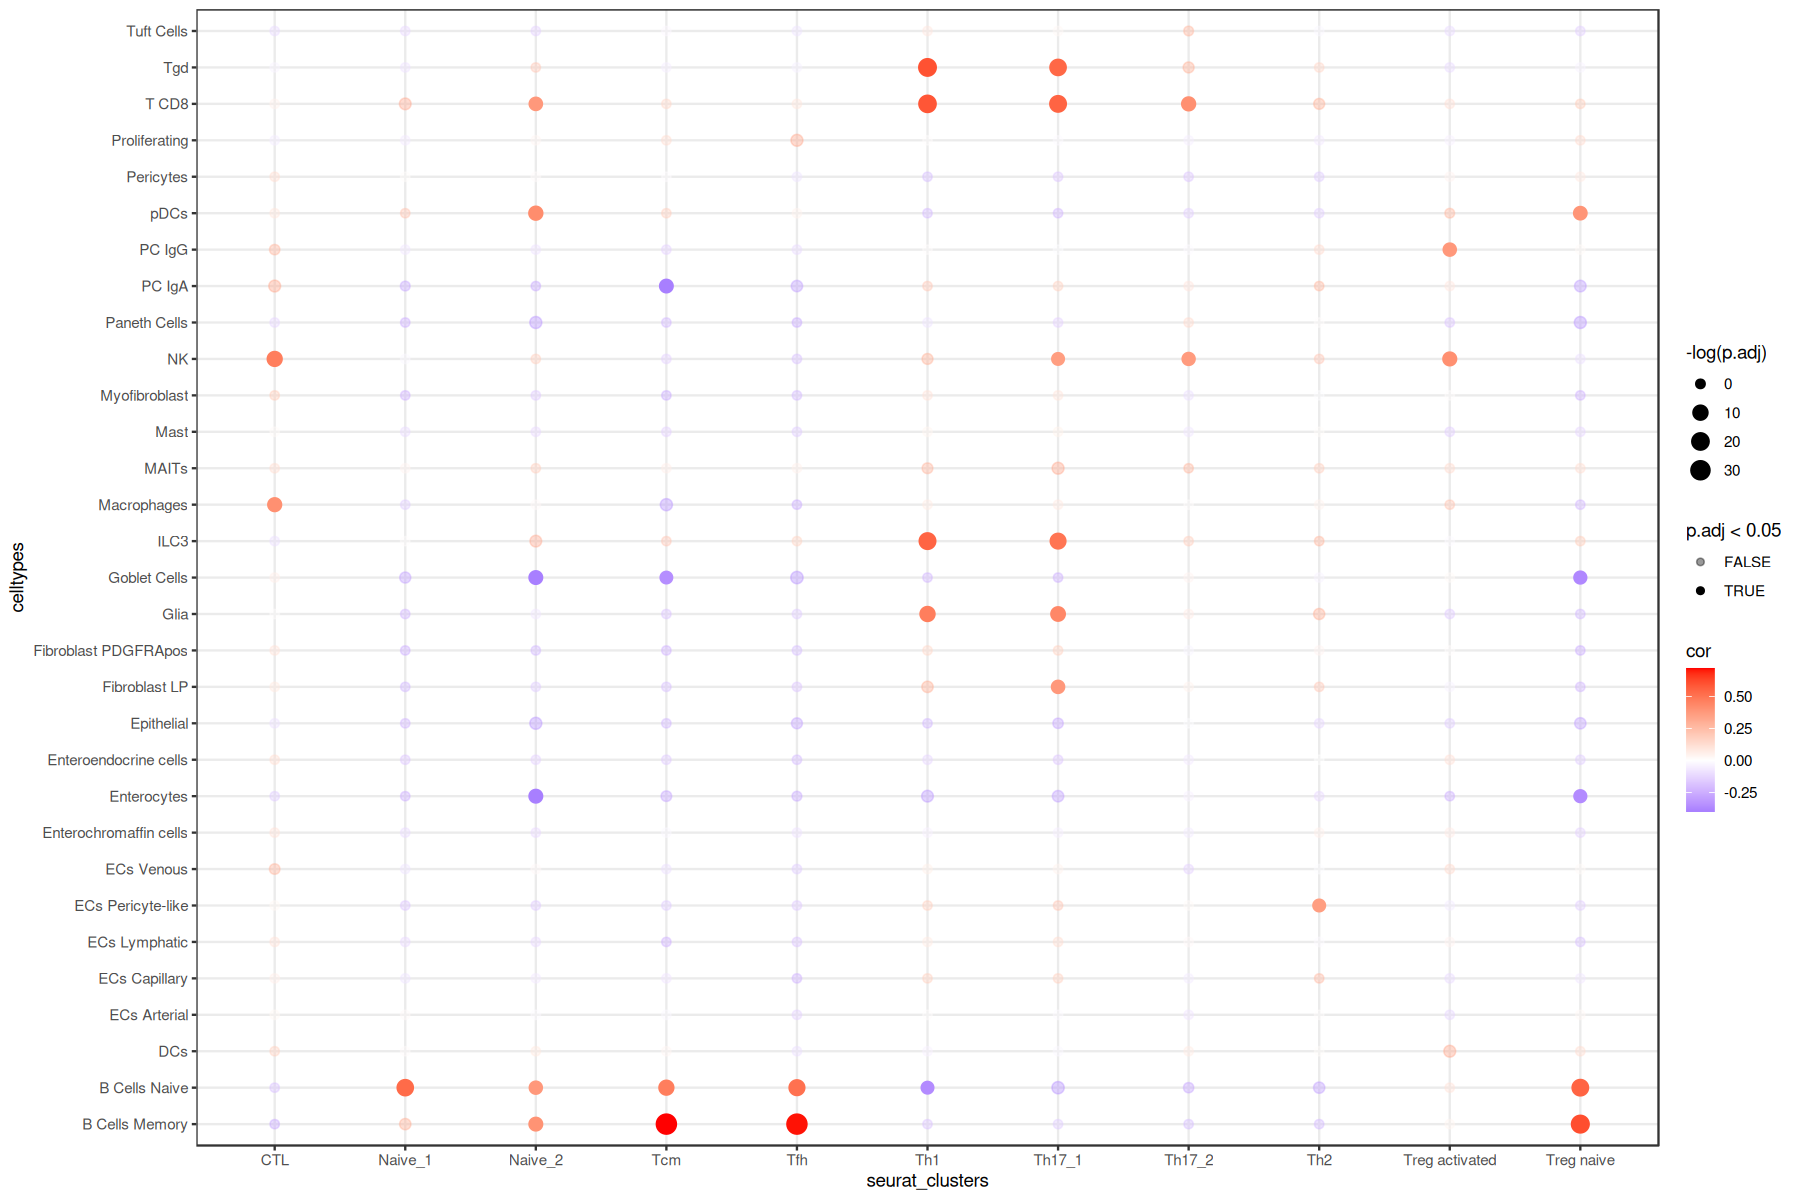

In [252]:
options(repr.plot.width = 15, repr.plot.height = 10)
stat_test_all  %>% 
ggplot(aes(x = celltypes, y = seurat_clusters)) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  coord_flip()


### Cell states without CD4 T

In [253]:
df_populations <- seu_ile_lp_filt@meta.data  %>% 
dplyr::filter(cell_type_lvl2 != "T CD4" & cell_type_lvl2 != "T Regulatory")  %>% 
dplyr::filter(!grepl(cell_state, pattern = "CD4"))  %>% 
dplyr::filter(!grepl(cell_state, pattern = "Treg"))  %>% 
group_by(data_folder, cell_state) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cell_state, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [254]:
df_populations

data_folder,celltypes,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,Activated M0 MMP9pos PLA2G2Dpos IL18pos APOEpos,0.0022529771
003-043_T0_ILE_LP_5p_GEX,Arterial EC,0.0016092694
003-043_T0_ILE_LP_5p_GEX,CD8 IEL CD69pos,0.0260701641
003-043_T0_ILE_LP_5p_GEX,CD8 IEL ITGAEpos CD69pos,0.0059542967
003-043_T0_ILE_LP_5p_GEX,CD8 IEL ITGAEpos ENTPD1pos,0.0020920502
003-043_T0_ILE_LP_5p_GEX,CD8 Killer Memory GZMKpos CCL4hi,0.0400708079
003-043_T0_ILE_LP_5p_GEX,CD8 Naive,0.0933376247
003-043_T0_ILE_LP_5p_GEX,CD8 Tcm/Tem,0.0159317670
003-043_T0_ILE_LP_5p_GEX,CD8 Tpex,0.0033794657


In [255]:
df_populations$celltypes  %>% table  %>% length

[1] 114

In [256]:
df_tcells <- seu_ile_lp_filt@meta.data  %>% 
group_by(data_folder, annotations) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = annotations, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "t_cell", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [257]:
df_tcells

data_folder,t_cell,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,CTL,0.0053655971
003-043_T0_ILE_LP_5p_GEX,Naive_1,0.1254076802
003-043_T0_ILE_LP_5p_GEX,Naive_2,0.0135718043
003-043_T0_ILE_LP_5p_GEX,Tcm,0.0631246712
003-043_T0_ILE_LP_5p_GEX,Tfh,0.0132561810
003-043_T0_ILE_LP_5p_GEX,Th1,0.0208311415
003-043_T0_ILE_LP_5p_GEX,Th17_1,0.0124145187
003-043_T0_ILE_LP_5p_GEX,Th17_2,0.0004208311
003-043_T0_ILE_LP_5p_GEX,Th2,0.0047343503


In [258]:
populations  <- levels(factor(seu_ile_lp_filt$annotations))

In [259]:
i = 1
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*116*11>1,1,p*116*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])


Joining with `by = join_by(data_folder)`


In [260]:
stat_test_all  <- stat_test

In [261]:
for(i in 2:11){
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*116*11>1,1,p*116*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])
    
    stat_test_all  <- rbind(stat_test_all, stat_test)
}

Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`


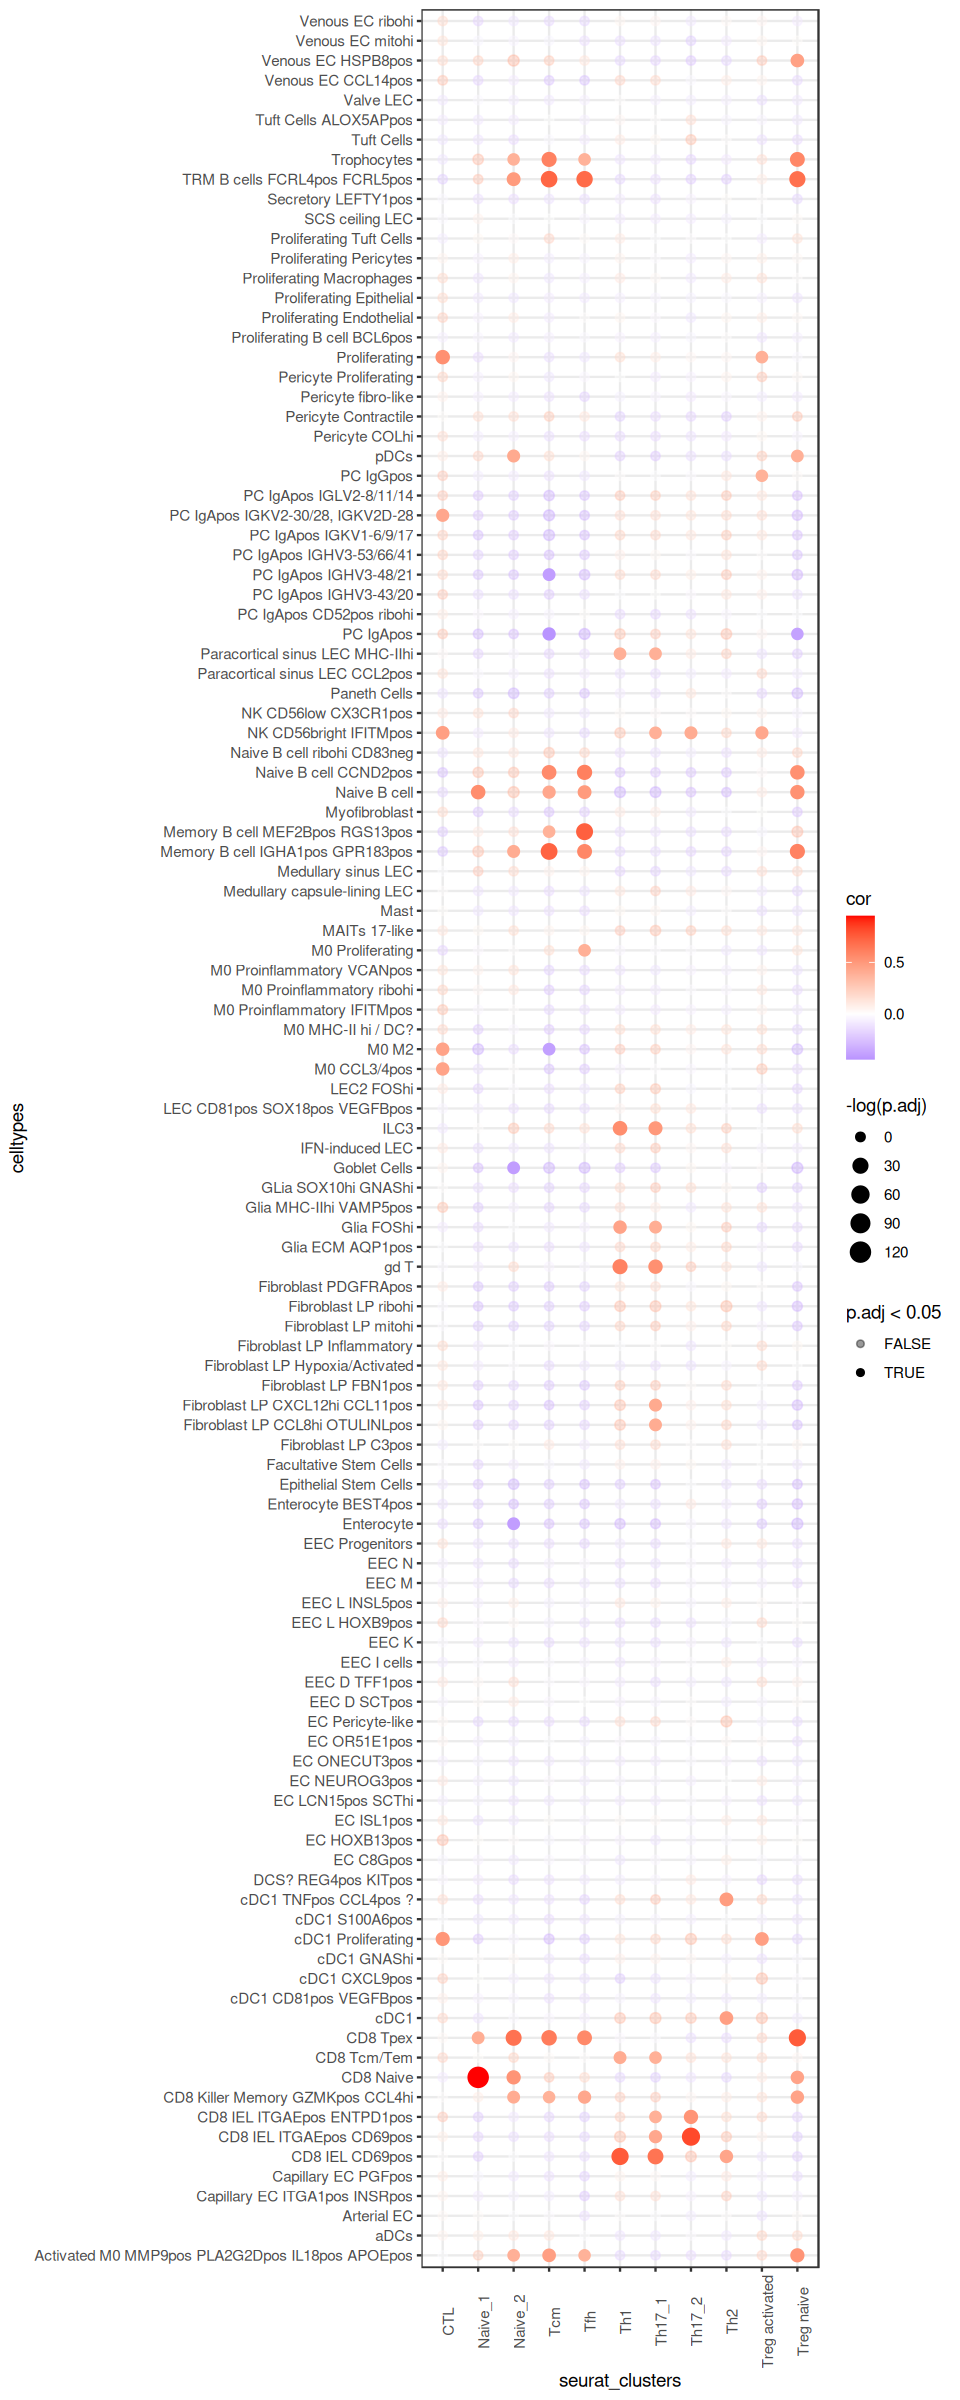

In [262]:
options(repr.plot.width = 8, repr.plot.height = 20)
stat_test_all  %>% 
ggplot(aes(x = celltypes, y = seurat_clusters)) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
theme(axis.text.x = element_text(angle = 90)) +
  coord_flip()


In [263]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,17648246,942.6,34172643,1825.1,34172643,1825.1
Vcells,4483856319,34209.2,11708443288,89328.4,9805887991,74813.0


## T cell subpopulations - freq from T cells

### Cell types level 2 without CD4 T

In [264]:
df_populations <- seu_ile_lp_filt@meta.data  %>% 
dplyr::filter(cell_type_lvl2 != "T CD4" & cell_type_lvl2 != "T Regulatory")  %>% 
group_by(data_folder, cell_type_lvl2) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cell_type_lvl2, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [265]:
df_populations

data_folder,celltypes,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,B Cells Memory,0.2367235275
003-043_T0_ILE_LP_5p_GEX,B Cells Naive,0.1754103637
003-043_T0_ILE_LP_5p_GEX,DCs,0.0083682008
003-043_T0_ILE_LP_5p_GEX,ECs Arterial,0.0016092694
003-043_T0_ILE_LP_5p_GEX,ECs Capillary,0.0057933698
003-043_T0_ILE_LP_5p_GEX,ECs Venous,0.0112648857
003-043_T0_ILE_LP_5p_GEX,Enterochromaffin cells,0.0003218539
003-043_T0_ILE_LP_5p_GEX,Enterocytes,0.0334728033
003-043_T0_ILE_LP_5p_GEX,Enteroendocrine cells,0.0001609269


In [266]:
df_populations$celltypes  %>% table  %>% length

[1] 31

In [267]:
df_tcells <- seu_ile_lp_filt@meta.data  %>% 
dplyr::filter(!is.na(annotations))  %>% 
group_by(data_folder, annotations) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = annotations, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "t_cell", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [268]:
df_tcells

data_folder,t_cell,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,CTL,0.015887850
003-043_T0_ILE_LP_5p_GEX,Naive_1,0.371339564
003-043_T0_ILE_LP_5p_GEX,Naive_2,0.040186916
003-043_T0_ILE_LP_5p_GEX,Tcm,0.186915888
003-043_T0_ILE_LP_5p_GEX,Tfh,0.039252336
003-043_T0_ILE_LP_5p_GEX,Th1,0.061682243
003-043_T0_ILE_LP_5p_GEX,Th17_1,0.036760125
003-043_T0_ILE_LP_5p_GEX,Th17_2,0.001246106
003-043_T0_ILE_LP_5p_GEX,Th2,0.014018692


In [269]:
populations  <- levels(factor(seu_ile_lp_filt$annotations))

In [270]:
i = 1
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*33*11>1,1,p*33*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])


Joining with `by = join_by(data_folder)`


In [271]:
stat_test_all  <- stat_test

In [272]:
for(i in 2:11){
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*33*11>1,1,p*33*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])
    
    stat_test_all  <- rbind(stat_test_all, stat_test)
}

Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`


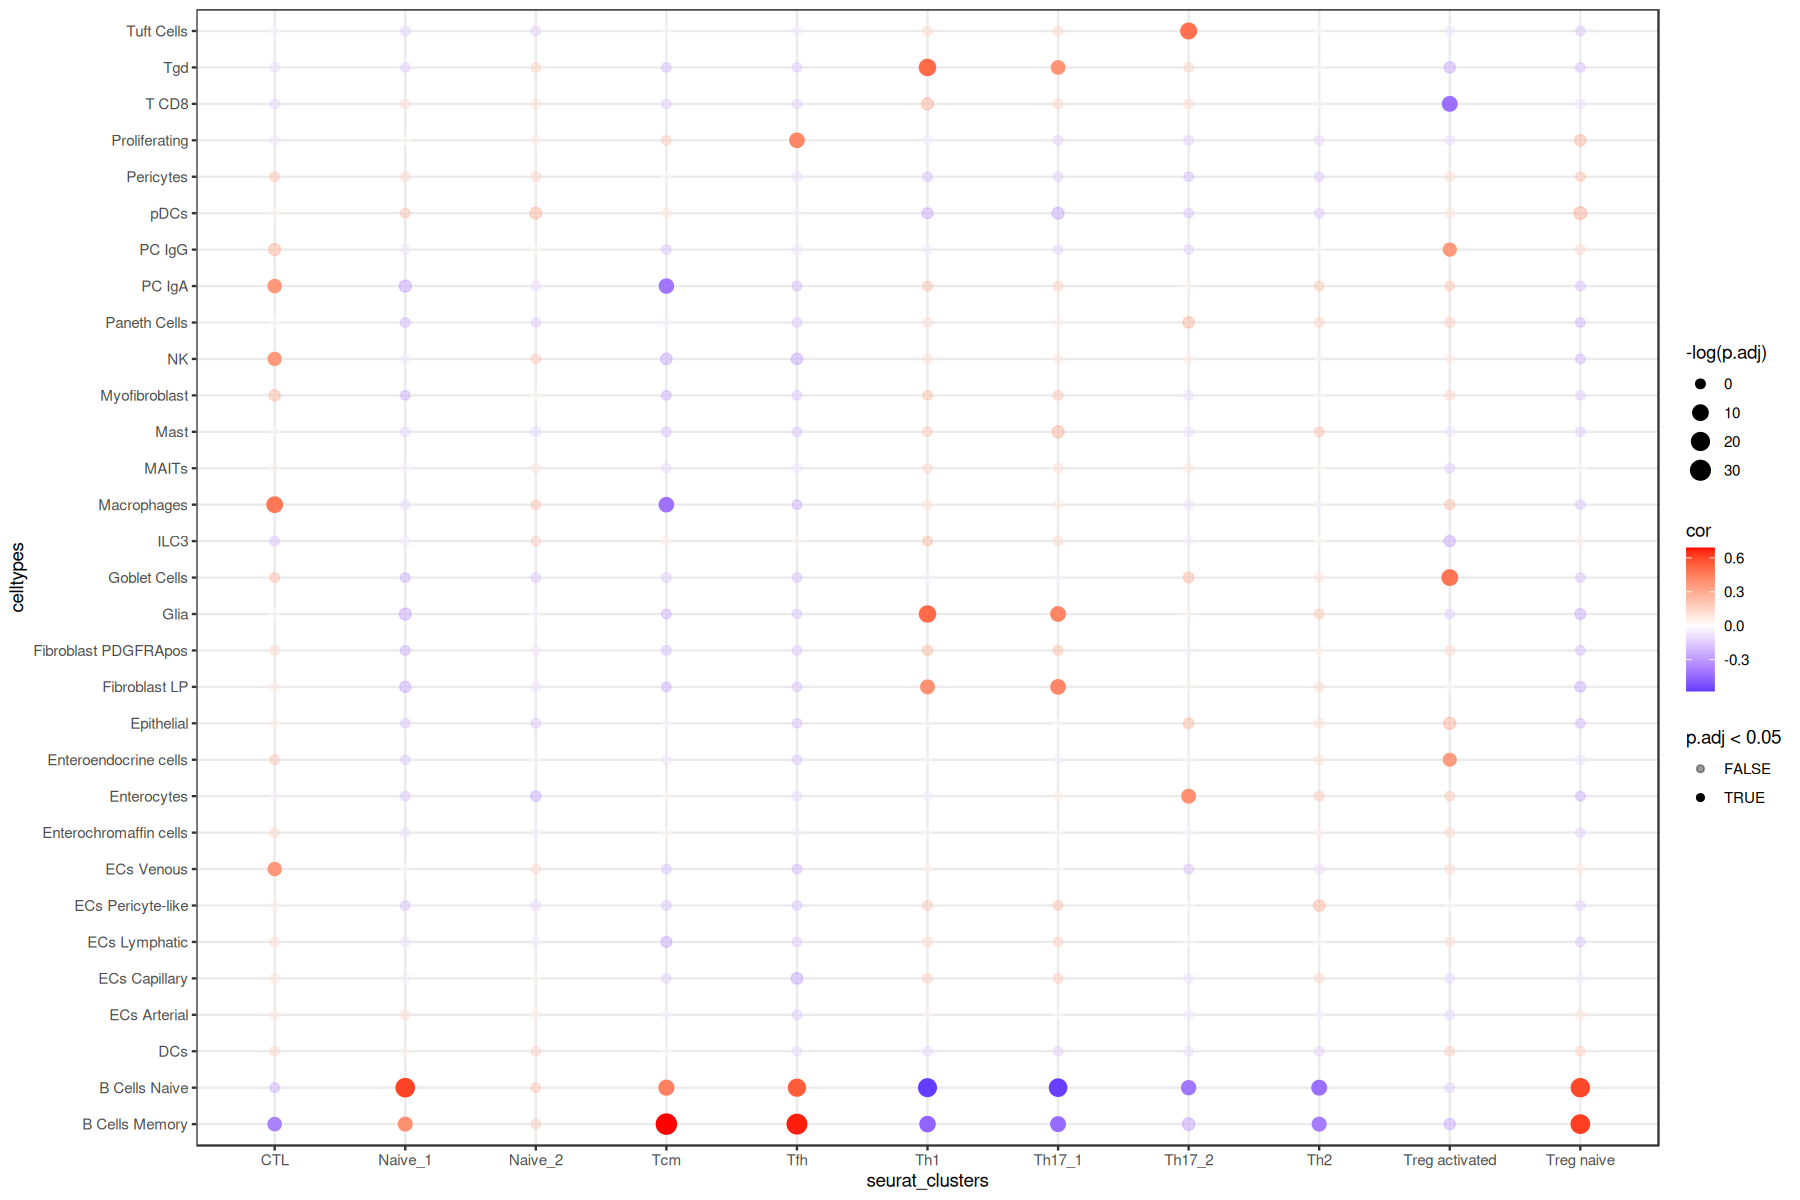

In [273]:
options(repr.plot.width = 15, repr.plot.height = 10)
stat_test_all  %>% 
ggplot(aes(x = celltypes, y = seurat_clusters)) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
  coord_flip()


### Cell states without CD4 T

In [274]:
df_populations <- seu_ile_lp_filt@meta.data  %>% 
dplyr::filter(cell_type_lvl2 != "T CD4" & cell_type_lvl2 != "T Regulatory")  %>% 
dplyr::filter(!grepl(cell_state, pattern = "CD4"))  %>% 
dplyr::filter(!grepl(cell_state, pattern = "Treg"))  %>% 
group_by(data_folder, cell_state) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = cell_state, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "celltypes", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [275]:
df_populations

data_folder,celltypes,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,Activated M0 MMP9pos PLA2G2Dpos IL18pos APOEpos,0.0022529771
003-043_T0_ILE_LP_5p_GEX,Arterial EC,0.0016092694
003-043_T0_ILE_LP_5p_GEX,CD8 IEL CD69pos,0.0260701641
003-043_T0_ILE_LP_5p_GEX,CD8 IEL ITGAEpos CD69pos,0.0059542967
003-043_T0_ILE_LP_5p_GEX,CD8 IEL ITGAEpos ENTPD1pos,0.0020920502
003-043_T0_ILE_LP_5p_GEX,CD8 Killer Memory GZMKpos CCL4hi,0.0400708079
003-043_T0_ILE_LP_5p_GEX,CD8 Naive,0.0933376247
003-043_T0_ILE_LP_5p_GEX,CD8 Tcm/Tem,0.0159317670
003-043_T0_ILE_LP_5p_GEX,CD8 Tpex,0.0033794657


In [276]:
df_populations$celltypes  %>% table  %>% length

[1] 114

In [277]:
df_tcells <- seu_ile_lp_filt@meta.data  %>% 
dplyr::filter(!is.na(annotations))  %>% 
group_by(data_folder, annotations) %>% 
  summarise(n = n()) %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = annotations, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "t_cell", values_to = "freq")

`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [278]:
df_tcells

data_folder,t_cell,freq
<chr>,<chr>,<dbl>
003-043_T0_ILE_LP_5p_GEX,CTL,0.015887850
003-043_T0_ILE_LP_5p_GEX,Naive_1,0.371339564
003-043_T0_ILE_LP_5p_GEX,Naive_2,0.040186916
003-043_T0_ILE_LP_5p_GEX,Tcm,0.186915888
003-043_T0_ILE_LP_5p_GEX,Tfh,0.039252336
003-043_T0_ILE_LP_5p_GEX,Th1,0.061682243
003-043_T0_ILE_LP_5p_GEX,Th17_1,0.036760125
003-043_T0_ILE_LP_5p_GEX,Th17_2,0.001246106
003-043_T0_ILE_LP_5p_GEX,Th2,0.014018692


In [279]:
populations  <- levels(factor(seu_ile_lp_filt$annotations))

In [280]:
i = 1
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*116*11>1,1,p*116*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])


Joining with `by = join_by(data_folder)`


In [281]:
stat_test_all  <- stat_test

In [282]:
for(i in 2:11){
to_join <- df_tcells  %>% dplyr::filter(t_cell == populations[i])  %>% 
dplyr::select(data_folder, freq_cl = freq)

df_2 <- df_populations   %>%  
left_join(to_join)

stat_test <- df_2  %>% 
group_by(celltypes)  %>% 
rstatix::cor_test(freq_cl, freq) %>% 
arrange(desc(cor))  %>% 
mutate(p.adj = ifelse(p*116*11>1,1,p*116*11))  %>% 
dplyr::select(celltypes, p.adj, cor)  %>% 
mutate(seurat_clusters = populations[i])
    
    stat_test_all  <- rbind(stat_test_all, stat_test)
}

Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`
Joining with `by = join_by(data_folder)`


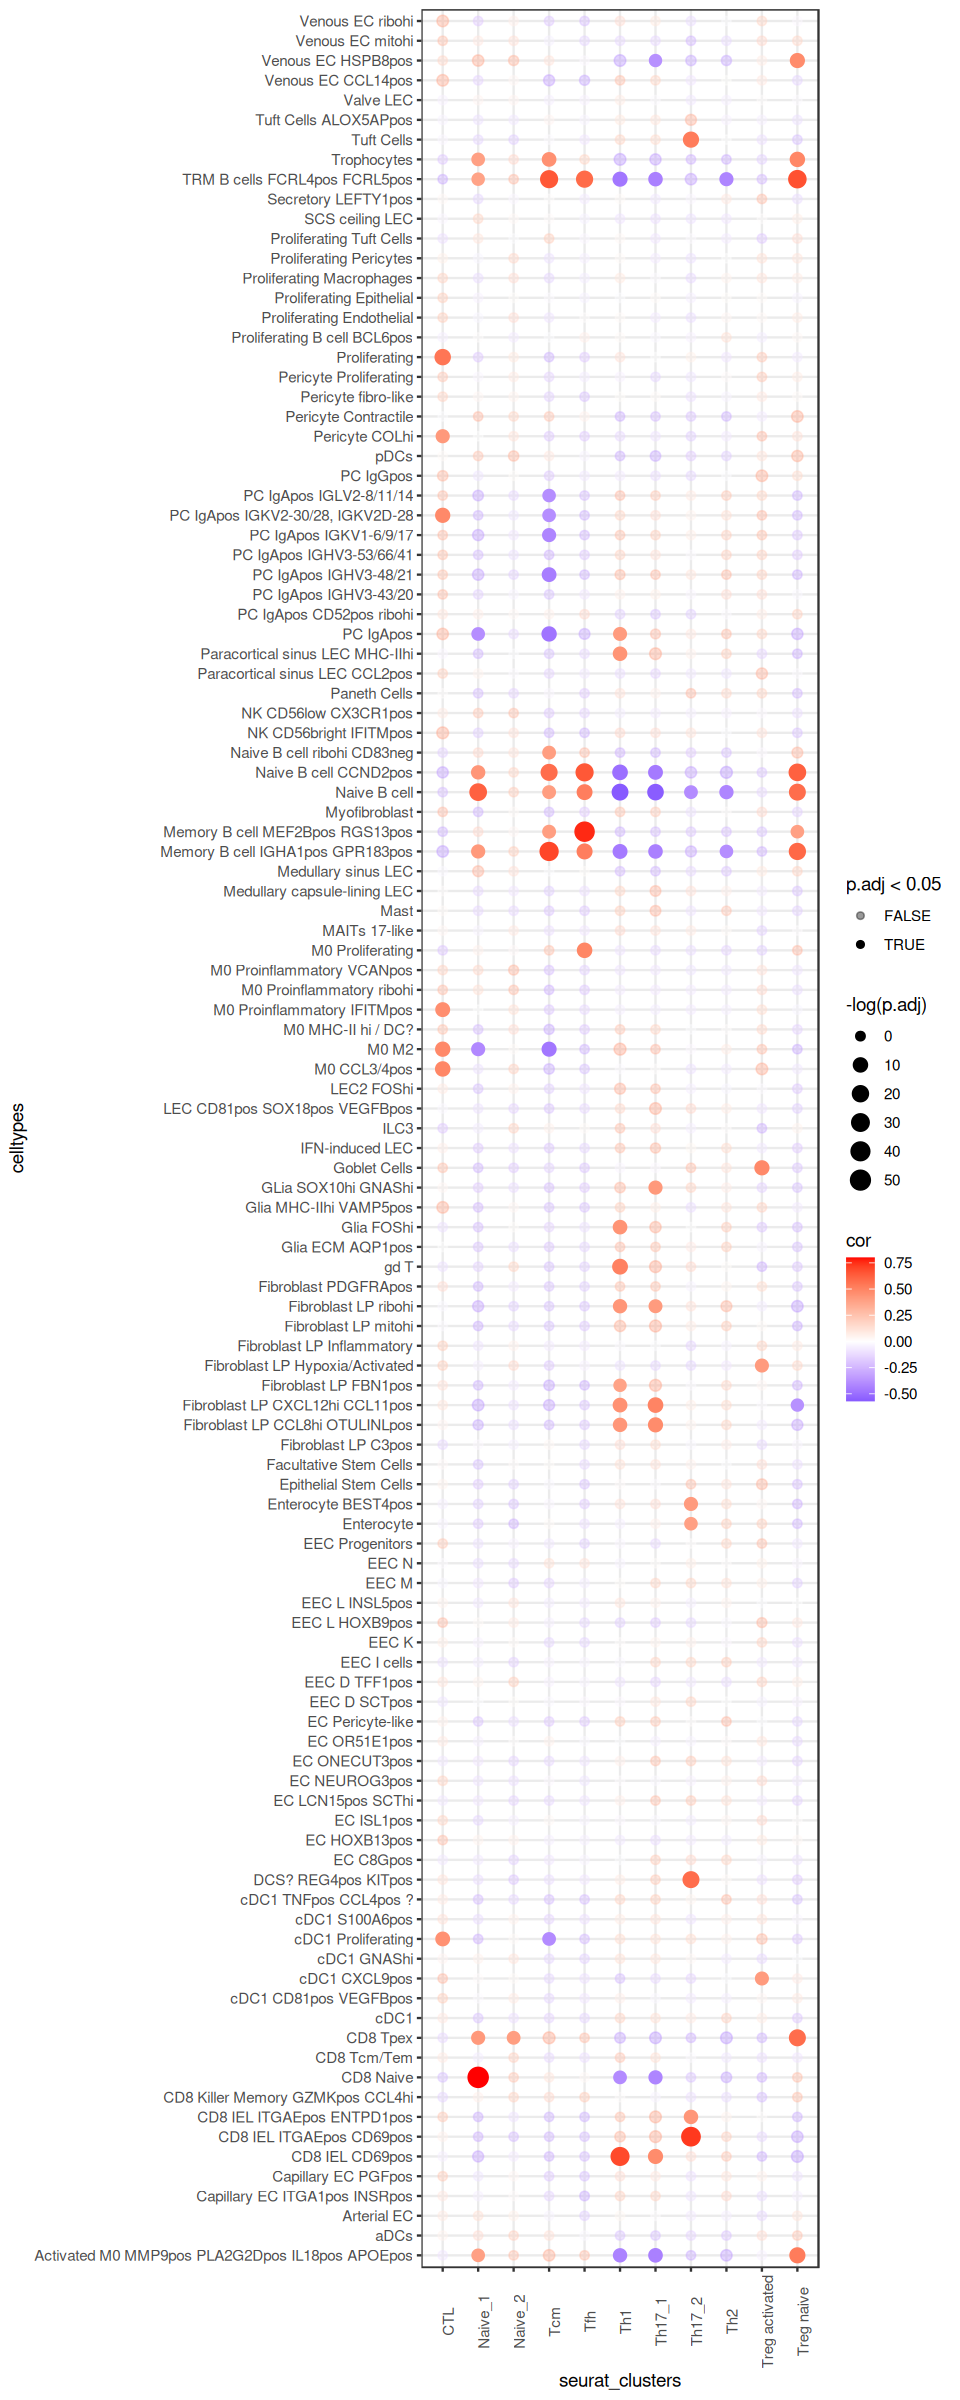

In [283]:
options(repr.plot.width = 8, repr.plot.height = 20)
stat_test_all  %>% 
ggplot(aes(x = celltypes, y = seurat_clusters)) +
  geom_point(aes(size = -log(p.adj), alpha = p.adj < 0.05, color = cor)) + 
  theme_bw() +
scale_size_continuous(range=c(2,5)) +
scale_alpha_manual(values = c(0.4,1)) +
scale_colour_gradient2(low = "blue", mid = "white", high = "red", midpoint = 0) +
theme(axis.text.x = element_text(angle = 90)) +
  coord_flip()


In [284]:
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,17648415,942.6,34172643,1825.1,34172643,1825.1
Vcells,4483856031,34209.2,11708443288,89328.4,9805887991,74813.0


## Ligand receptor interactions

In [285]:
seu_ile_lp

An object of class Seurat 
36601 features across 1040968 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [34]:
seu_ile_lp_filt

An object of class Seurat 
36601 features across 672820 samples within 1 assay 
Active assay: RNA (36601 features, 0 variable features)
 1 layer present: counts

In [37]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

from,to
<chr>,<chr>
A2M,MMP2
A2M,MMP9
A2M,LRP1
A2M,KLK3
AANAT,MTNR1A
AANAT,MTNR1B


In [38]:
seu_ile_lp_filt$cd4_ctl  <- FALSE

In [39]:
seu_ile_lp_filt$cd4_ctl  <- if_else(seu_ile_lp_filt$annotations == "CTL",TRUE,FALSE)

In [40]:
seu_ile_lp_filt$cd4_ctl  <- ifelse(is.na(seu_ile_lp_filt$cd4_ctl),FALSE,seu_ile_lp_filt$cd4_ctl)

In [41]:
seu_ile_lp_filt@meta.data  <- seu_ile_lp_filt@meta.data  %>% 
mutate(cell_type_lvl2 = if_else(grepl(cell_type_lvl2, pattern = "T "), "T cells", cell_type_lvl2))

In [42]:
seu_ile_lp_filt@meta.data   %>% group_by(cd4_ctl, cell_type_lvl2)  %>% tally

cd4_ctl,cell_type_lvl2,n
<lgl>,<chr>,<int>
FALSE,B Cells Memory,75250
FALSE,B Cells Naive,58355
FALSE,DCs,5466
FALSE,ECs Arterial,705
FALSE,ECs Capillary,3678
FALSE,ECs Lymphatic,1295
FALSE,ECs Pericyte-like,1291
FALSE,ECs Venous,5251
FALSE,Enterochromaffin cells,221


In [43]:
seu_ile_lp_filt@meta.data  <- seu_ile_lp_filt@meta.data  %>% 
mutate(combinedMajorTypes_plus_cd4_ctl = if_else(cd4_ctl, "CD4_CTL", cell_type_lvl2))

In [44]:
seu_ile_lp_filt$combinedMajorTypes_plus_cd4_ctl  %>% table

.
        B Cells Memory          B Cells Naive                CD4_CTL 
                 75250                  58355                   5944 
                   DCs           ECs Arterial          ECs Capillary 
                  5466                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
           Macrophages                  MAITs                   Mast 
                 30493                   2929                  17045 
         Myofibrob

In [45]:
DefaultAssay(seu_ile_lp_filt)  <- "RNA"

In [46]:
seu_ile_lp_filt$cellsubsets_plus_cd4_ctl  <- ifelse(seu_ile_lp_filt$cd4_ctl, "CD4_CTL",seu_ile_lp_filt$cell_type_lvl2)

In [47]:
seu_ile_lp_filt$cellsubsets_plus_cd4_ctl  %>% table

.
        B Cells Memory          B Cells Naive                CD4_CTL 
                 75250                  58355                   5944 
                   DCs           ECs Arterial          ECs Capillary 
                  5466                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
           Macrophages                  MAITs                   Mast 
                 30493                   2929                  17045 
         Myofibrob

In [48]:
colnames(seu_ile_lp_filt@meta.data)

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "bc"                             
 [5] "data_folder"                     "data_folder2"                   
 [7] "sample"                          "diagnosis"                      
 [9] "subgroup_primary"                "subgroup_secondary"             
[11] "subgroup_tertiary"               "Rome_coarse"                    
[13] "Rome_classification"             "antitnf_response"               
[15] "participant_id"                  "timepoint"                      
[17] "age"                             "sex"                            
[19] "site"                            "tissue"                         
[21] "layer"                           "prime"                          
[23] "version_10x"                     "sample_old"                     
[25] "data_type"                       "seq_run"                        
[27] "collection_purpose"              "collection_date"                
[29] "days"                            "antitnf"                        
[31] "antitnf_repeat"                  "duo_inflammation"               
[33] "ile_inflammation"                "col_inflammation"               
[35] "sample_inflamed"                 "colon_site"                     
[37] "score_type"                      "severity_score"                 
[39] "weighted_severity_score"         "severity_score_date"            
[41] "severity_score_range"            "weighted_score_range"           
[43] "internal_flag"                   "cell_lineage"                   
[45] "cell_type_lvl1"                  "cell_type_lvl2"                 
[47] "cell_state"                      "keep"                           
[49] "annotations"                     "cd4_ctl"                        
[51] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [49]:
Idents(seu_ile_lp_filt)  <- seu_ile_lp_filt$combinedMajorTypes_plus_cd4_ctl

In [50]:
library(nichenetr)


Attaching package: ‘nichenetr’


The following object is masked _by_ ‘.GlobalEnv’:

    lr_network




In [51]:
receiver = "CD4_CTL"
expressed_genes_receiver <- get_expressed_genes(receiver, seu_ile_lp_filt, pct = 0.05)

Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”


In [52]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [53]:
expressed_receptors

[1] "TIGIT"     "NOTCH2"    "CD44"      "NOTCH1"    "TSPAN5"    "TSPAN14"  
  [7] "TSPAN17"   "ITGA4"     "CCR4"      "SDC4"      "ITGB1"     "ITGA5"    
 [13] "IL6R"      "ITGB7"     "ITGAV"     "CD55"      "ADIPOR1"   "ADIPOR2"  
 [19] "ADRB2"     "CD6"       "CD63"      "LAMP1"     "LAMP2"     "ITGA1"    
 [25] "ABCA1"     "LDLR"      "ITGB2"     "SORL1"     "NCSTN"     "CD74"     
 [31] "MGRN1"     "TAP1"      "TAP2"      "SELPLG"    "NTRK2"     "BMPR2"    
 [37] "ENG"       "TGFBR1"    "TGFBR2"    "PLAUR"     "TNFRSF14"  "CD247"    
 [43] "JAML"      "C3AR1"     "CD46"      "IL2RG"     "LRCH4"     "CCR5"     
 [49] "CXCR3"     "DPP4"      "CCR7"      "CCR6"      "CCR9"      "IGF2R"    
 [55] "IL6ST"     "CD53"      "CD200R1"   "ICAM3"     "PTPRC"     "CD79B"    
 [61] "LAT"       "PDCD1"     "NCR3"      "CD4"       "LRPAP1"    "TMEM167A" 
 [67] "CD40LG"    "SIRPG"     "CD2"       "CD244"     "ADGRE5"    "CD5"      
 [73] "ADAM15"    "CD27"      "SEMA4D"    "CD274"     "CD28"      "CTLA4"    
 [79] "CD37"      "IGSF8"     "CD99"      "CD81"      "KLRG1"     "ITGAE"    
 [85] "PTPRM"     "BTN3A1"    "CD3D"      "HAVCR2"    "CD8A"      "UXS1"     
 [91] "BTN2A2"    "CXCR4"     "KLRB1"     "CLEC2B"    "LAG3"      "IL23R"    
 [97] "FCGRT"     "SLAMF1"    "LAIR1"     "TNFRSF10A" "CD47"      "LIN7C"    
[103] "PATJ"      "GNAS"      "A1BG"      "F2R"       "CXCR6"     "GPR35"    
[109] "CD151"     "RPSA"      "IL27RA"    "ECE1"      "EVC2"      "ADORA2A"  
[115] "ITGAL"     "TRAF2"     "SLC9A1"    "CLEC2D"    "FAS"       "ADAM19"   
[121] "ORAI2"     "CD82"      "AMFR"      "TNFRSF1A"  "TNFRSF1B"  "MCL1"     
[127] "EZR"       "BTN3A3"    "TMIGD2"    "NEO1"      "APLP2"     "IL2RA"    
[133] "SPN"       "MSN"       "ICOS"      "IFNAR1"    "IFNAR2"    "IFNGR1"   
[139] "IL10RB"    "TRPV2"     "IGFLR1"    "VSIR"      "IL10RA"    "IL12RB1"  
[145] "IL12RB2"   "IL4R"      "IL15RA"    "IL2RB"     "KCNA3"     "IL17RA"   
[151] "IL17RE"    "IL18R1"    "IL18RAP"   "SIGIRR"    "IL21R"     "BCL2"     
[157] "IL7R"      "TGFBR3"    "CD226"     "ICAM1"     "CD320"     "RTN4"     
[163] "MPZL3"     "LMBR1L"    "CD69"      "ANXA2"     "SLC1A5"    "LPAR2"    
[169] "BTN3A2"    "TMEM123"   "TFRC"      "C1QB"      "HCST"      "KIAA0319L"
[175] "CD96"      "NPTN"      "ERAP1"     "HLA-DRB1"  "FURIN"     "CD38"     
[181] "OGFR"      "PIGR"      "PLGRKT"    "TYROBP"    "TNFRSF25"  "PSEN1"    
[187] "JMJD6"     "ATP6AP2"   "GPR25"     "PTPRJ"     "ADAM12"    "CD7"      
[193] "GLG1"      "PLXNC1"    "SLC37A1"   "S1PR1"     "LRP12"     "TMEM216"  
[199] "TCTN3"     "ADAM17"    "BTLA"      "TNFRSF10B" "TNFRSF18"  "TNFRSF4"  
[205] "MAP4K2"    "ADAM10"    "RYK"       "TMED5"

In [54]:
potential_ligands

[1] "ACE2"      "ADAM10"    "ADAM11"    "ADAM12"    "ADAM15"    "ADAM17"   
  [7] "ADAM2"     "ADAM23"    "ADAM28"    "ADAM29"    "ADAM7"     "ADAM9"    
 [13] "ADGRE5"    "ADIPOQ"    "ADM2"      "AGRN"      "ALCAM"     "AMBN"     
 [19] "AMELX"     "AMELY"     "ANGPT1"    "ANGPT2"    "ANGPTL1"   "ANGPTL2"  
 [25] "ANGPTL3"   "ANGPTL4"   "APOA1"     "APOA2"     "APOA4"     "APOB"     
 [31] "APOC2"     "APOC3"     "APOE"      "APP"       "ASIP"      "AZGP1"    
 [37] "B2M"       "BACE1"     "BDNF"      "BMP1"      "BMP10"     "BMP15"    
 [43] "BMP2"      "BMP3"      "BMP4"      "BMP5"      "BMP6"      "BMP7"     
 [49] "BMP8A"     "BMP8B"     "BTLA"      "BTN1A1"    "BTNL9"     "C3"       
 [55] "C4A"       "C4B_2"     "C4BPA"     "CADM3"     "CALR"      "CCL1"     
 [61] "CCL11"     "CCL13"     "CCL14"     "CCL16"     "CCL17"     "CCL18"    
 [67] "CCL19"     "CCL2"      "CCL20"     "CCL21"     "CCL22"     "CCL25"    
 [73] "CCL26"     "CCL3"      "CCL3L1"    "CCL3L3"    "CCL4"      "CCL4L1"   
 [79] "CCL4L2"    "CCL5"      "CCL7"      "CCL8"      "CCN1"      "CCN2"     
 [85] "CCN3"      "CCN4"      "CCN6"      "CD160"     "CD1B"      "CD2"      
 [91] "CD200"     "CD209"     "CD22"      "CD244"     "CD274"     "CD28"     
 [97] "CD320"     "CD40"      "CD40LG"    "CD47"      "CD48"      "CD55"     
[103] "CD58"      "CD59"      "CD5L"      "CD7"       "CD70"      "CD72"     
[109] "CD79B"     "CD80"      "CD82"      "CD86"      "CD9"       "CD99"     
[115] "CDH1"      "CDH9"      "CDHR2"     "CEACAM1"   "CEACAM5"   "CEACAM6"  
[121] "CEACAM8"   "CEL"       "CGA"       "CHAD"      "CKLF"      "CLCF1"    
[127] "CLEC11A"   "CLEC2A"    "CLEC2B"    "CLEC2D"    "CLEC2L"    "CLEC3A"   
[133] "CLEC4G"    "CLMP"      "CNTF"      "CNTN1"     "CNTN5"     "CNTN6"    
[139] "COL10A1"   "COL11A1"   "COL11A2"   "COL12A1"   "COL13A1"   "COL14A1"  
[145] "COL15A1"   "COL16A1"   "COL17A1"   "COL18A1"   "COL19A1"   "COL1A1"   
[151] "COL1A2"    "COL20A1"   "COL21A1"   "COL22A1"   "COL24A1"   "COL26A1"  
[157] "COL27A1"   "COL28A1"   "COL2A1"    "COL3A1"    "COL4A1"    "COL4A2"   
[163] "COL4A3"    "COL4A4"    "COL4A5"    "COL4A6"    "COL5A1"    "COL5A2"   
[169] "COL5A3"    "COL6A1"    "COL6A2"    "COL6A3"    "COL6A5"    "COL6A6"   
[175] "COL7A1"    "COL8A1"    "COL8A2"    "COL9A1"    "COL9A2"    "COL9A3"   
[181] "COMP"      "COPA"      "CRB3"      "CRHR2"     "CRISP3"    "CRLF1"    
[187] "CTF1"      "CTSG"      "CX3CL1"    "CXADR"     "CXCL10"    "CXCL11"   
[193] "CXCL12"    "CXCL13"    "CXCL14"    "CXCL16"    "CXCL17"    "CXCL2"    
[199] "CXCL9"     "DBH"       "DEFB1"     "DEFB103B"  "DEFB4A"    "DEFB4B"   
[205] "DLK1"      "DLK2"      "DLL1"      "DLL3"      "DLL4"      "DMP1"     
[211] "DSCAM"     "DSCAML1"   "DSPP"      "DUSP18"    "EBI3"      "EDIL3"    
[217] "EDN1"      "EFNB1"     "EGFL8"     "ENAM"      "ENG"       "ENTPD1"   
[223] "ESM1"      "EXOC3-AS1" "EZR"       "F10"       "F11R"      "F13A1"    
[229] "F2"        "F8"        "FAM200A"   "FAM3C"     "FAP"       "FASLG"    
[235] "FBLN1"     "FBN1"      "FCAR"      "FCER2"     "FGA"       "FGB"      
[241] "FGF2"      "FGF6"      "FGG"       "FGL1"      "FN1"       "FNDC5"    
[247] "FSHB"      "FST"       "FSTL5"     "FURIN"     "GCG"       "GDF1"     
[253] "GDF10"     "GDF11"     "GDF2"      "GDF5"      "GDF6"      "GDF7"     
[259] "GDF9"      "GGT1"      "GHRH"      "GIP"       "GNAS"      "GP1BA"    
[265] "GP5"       "GPC3"      "GPI"       "GRN"       "GSTP1"     "GZMB"     
[271] "HAS1"      "HAS2"      "HAVCR1"    "HBEGF"     "HGF"       "HHLA2"    
[277] "HJV"       "HLA-A"     "HLA-B"     "HLA-DMA"   "HLA-DMB"   "HLA-DOA"  
[283] "HLA-DOB"   "HLA-DPB1"  "HLA-DQA1"  "HLA-DQA2"  "HLA-DQB1"  "HLA-DQB2" 
[289] "HLA-DRA"   "HLA-DRB1"  "HLA-DRB3"  "HLA-DRB4"  "HLA-DRB5"  "HLA-E"    
[295] "HLA-F"     "HLA-G"     "HMGB1"     "HP"        "HSPG2"     "IBSP"     
[301] "ICAM1"     "ICAM2"     "ICAM3"     "ICAM4"     "ICAM5"     "ICOSLG"   
[307] "IFITM1"    "IFNA1

In [60]:
seu_ile_lp_filt$combinedMajorTypes_plus_cd4_ctl  %>% table

.
        B Cells Memory          B Cells Naive                CD4_CTL 
                 75250                  58355                   5944 
                   DCs           ECs Arterial          ECs Capillary 
                  5466                    705                   3678 
         ECs Lymphatic      ECs Pericyte-like             ECs Venous 
                  1295                   1291                   5251 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial          Fibroblast LP   Fibroblast PDGFRApos 
                 41991                  22610                   5500 
                  Glia           Goblet Cells                   ILC3 
                  1749                  10282                   5227 
           Macrophages                  MAITs                   Mast 
                 30493                   2929                  17045 
         Myofibrob

In [62]:
seu_ile_lp_filt$diagnosis  %>% table

.
     CD    FGID     HEA     OTH      UC Unknown 
 331271  141443   66601   15959  106748   10798 

In [63]:
condition_oi <-  "CD"
condition_reference <- "FGID"

seurat_obj_receiver <- subset(seu_ile_lp_filt, combinedMajorTypes_plus_cd4_ctl %in% c("T cells","CD4_CTL"))

In [64]:
seurat_obj_receiver  <- NormalizeData(seurat_obj_receiver)
seurat_obj_receiver  <- ScaleData(seurat_obj_receiver)


Normalizing layer: counts

Centering and scaling data matrix



In [65]:
DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "diagnosis") 

In [70]:
table(rowSums(seurat_obj_receiver@assays$RNA@layers$counts)>5)


FALSE  TRUE 
11875 24726 

In [71]:
DE_table_receiver$gene  <- rownames(DE_table_receiver)

In [76]:
DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25)  %>% 
dplyr::filter(!grepl(gene, pattern = "^IG[KLH]"))

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
REG1A,0.000000e+00,2.1373472,0.262,0.086,0.000000e+00,REG1A
STAT1,0.000000e+00,1.0884415,0.435,0.297,0.000000e+00,STAT1
GBP5,0.000000e+00,1.2294120,0.290,0.176,0.000000e+00,GBP5
DEFA5,0.000000e+00,1.1652668,0.266,0.153,0.000000e+00,DEFA5
TFF3,0.000000e+00,2.5636909,0.110,0.023,0.000000e+00,TFF3
HLA-DRA,0.000000e+00,0.8020883,0.193,0.114,0.000000e+00,HLA-DRA
CXCR4,0.000000e+00,-0.2611238,0.782,0.855,0.000000e+00,CXCR4
SPINK4,0.000000e+00,3.8547723,0.078,0.007,0.000000e+00,SPINK4
LYZ,0.000000e+00,1.6692245,0.104,0.035,0.000000e+00,LYZ


In [79]:
geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% 
dplyr::filter(!grepl(gene, pattern = "^IG[KLH]"))  %>% pull(gene)

geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]  

In [80]:
geneset_oi

[1] "REG1A"        "STAT1"        "GBP5"         "DEFA5"       
   [5] "TFF3"         "HLA-DRA"      "CXCR4"        "SPINK4"      
   [9] "LYZ"          "DNAJB1"       "DEFA6"        "MUC2"        
  [13] "OLFM4"        "REG3A"        "ENTPD1"       "AGR2"        
  [17] "PLA2G2A"      "PIGR"         "REG1B"        "CLCA1"       
  [21] "CD74"         "CD81"         "RPS4Y1"       "PHGR1"       
  [25] "IRF9"         "KRT8"         "IRF1"         "GBP1"        
  [29] "HLA-DRB1"     "GPR183"       "GBP4"         "RNF213"      
  [33] "FOS"          "ETV7"         "HLA-DPB1"     "GBP2"        
  [37] "UBALD2"       "IL12RB2"      "HLA-DRB5"     "MT1G"        
  [41] "MT2A"         "EPSTI1"       "MT1E"         "LGALS4"      
  [45] "IFI44L"       "HLA-DPA1"     "FOXP3"        "PSME2"       
  [49] "C1QB"         "CXCL9"        "ADAM12"       "TYMP"        
  [53] "IFI30"        "GPR18"        "IFI27"        "ZNRF1"       
  [57] "TPSAB1"       "PDE3B"        "PRSS2"        "NEAT1"       
  [61] "CXCR6"        "LAYN"         "EFHD2"        "XAF1"        
  [65] "C1QA"         "LCN2"         "ALYREF"       "MIR4435-2HG" 
  [69] "CXCR5"        "TMEM238"      "MBD2"         "SPINK1"      
  [73] "KSR2"         "ANXA1"        "PRDM1"        "RASGEF1B"    
  [77] "GNLY"         "TAF10"        "EPCAM"        "CCR7"        
  [81] "REG4"         "DRAIC"        "PSMB9"        "LAIR1"       
  [85] "ACTN1"        "C1QC"         "CHN1"         "STK24"       
  [89] "NCF1"         "IL1R2"        "ZNRF2"        "UBE2M"       
  [93] "CTSH"         "CYTOR"        "TNFRSF18"     "HLA-DQA2"    
  [97] "FURIN"        "IFITM3"       "OAS1"         "DMBT1"       
 [101] "MAP2K2"       "PREX1"        "PARP14"       "MAN1A1"      
 [105] "HOPX"         "UBE2L6"       "TAP1"         "APOE"        
 [109] "SIK3"         "CTSZ"         "MAPKAPK2"     "CCR6"        
 [113] "SLC35D2"      "LINC02694"    "PARP9"        "VEGFB"       
 [117] "GNAI2"        "SYNE2"        "KANSL1-AS1"   "CAPNS1"      
 [121] "KRT18"        "IL1R1"        "IL6R"         "CCNY"        
 [125] "KLRG1"        "BTBD6"        "KRT19"        "ARMH1"       
 [129] "MZB1"         "TSPAN8"       "TFRC"         "TPSB2"       
 [133] "SERPINA1"     "EIF4E3"       "GPX2"         "NCK2"        
 [137] "PDCD1"        "HAPLN3"       "LINC00402"    "LYPD3"       
 [141] "SESN1"        "GLUL"         "RTKN2"        "LGALS3"      
 [145] "KLRB1"        "GOLIM4"       "APOC1"        "PPP1R14B"    
 [149] "TGFB1"        "IFI6"         "LY6E"         "CADM1"       
 [153] "DUSP4"        "PSMB8"        "HLA-DQA1"     "PPP1R2C"     
 [157] "IL21"         "PTP4A2"       "LIMS2"        "PTPRCAP"     
 [161] "CHRM3-AS2"    "SLC38A2"      "CTDNEP1"      "GRK2"        
 [165] "DUS1L"        "ITLN1"        "SAT1"         "KRT20"       
 [169] "ABHD17A"      "CBX4"         "C15orf48"     "CASK"        
 [173] "NFATC1"       "BATF"         "DDX3Y"        "CCR2"        
 [177] "AKT1"         "APOL6"        "METRNL"       "FBLN7"       
 [181] "TRIM22"       "SPATS2L"      "SPINK2"       "MATK"        
 [185] "TYROBP"       "KLF2"         "CCL25"        "GSK3A"       
 [189] "LRRN3"        "SLC12A2"      "CPA3"         "QKI"         
 [193] "ADAM19"       "CTBP1"        "RANBP9"       "ZFPM1"       
 [197] "GNG4"         "ST8SIA1"      "ZBTB7A"       "RAB3A"       
 [201] "OTUD5"        "CDV3"         "IL18R1"       "SH3GLB2"     
 [205] "UTY"          "TNFRSF9"      "PTPRJ"        "PHC2"        
 [209] "ACP5"         "MDS2"         "N4BP1"        "SYT11"       
 [213] "CUL3"         "HNRNPD"       "IL2RA"        "ZDHHC18"     
 [217] "PABPN1"       "TXNDC5"       "PTPN14"       "OASL"        
 [221] "METRN"        "HNRNPL"       "CCR8"         "CCNG2"       
 [225] "GIPC1"        "RAPGEF1"      "LINC01281"    "MTHFD2"      
 [229] "HNRNPUL2"     "ABCC1"        "HRH2"         "SAMD9L"      
 [233] "NBEAL2"       "NFE2L3"       "SMAP2"        "TNFSF12"     
 [237] "BTN3A1"       "MICAL2"       "CLDN3"      

In [81]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 7540

[1] 1057

In [82]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

Warning message in evaluate_target_prediction(setting, ligand_target_matrix, ligands_position):
“all target gene probability score predictions have same value”
Warning message in cor(prediction, response):
“the standard deviation is zero”
Warning message in cor(prediction, response, method = "s"):
“the standard deviation is zero”


In [83]:
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ACE2,0.5484714,0.1816356,0.04909638,0.07701295
ADAM10,0.5430676,0.1749172,0.04237806,0.06543093
ADAM11,0.5195895,0.1653178,0.03277858,0.03290430
ADAM12,0.5325549,0.1753561,0.04281696,0.05112793
ADAM15,0.5221603,0.1642537,0.03171453,0.03239799
ADAM17,0.5493619,0.1794110,0.04687181,0.05531087
ADAM2,0.5368150,0.1734673,0.04092816,0.05354562
ADAM23,0.5386351,0.1710923,0.03855316,0.04487189
ADAM28,0.5315536,0.1664117,0.03387255,0.04534598


In [84]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities 

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
IGFL3,0.5000000,0.5662696,0.43373041,NA
IFNG,0.5755240,0.2315532,0.09901405,0.18928598
TGFB1,0.6011744,0.2210664,0.08852718,0.17397315
IL27,0.5476495,0.2193275,0.08678832,0.17534569
IFNA1,0.5524670,0.2181729,0.08563372,0.17400292
IFNL3,0.5315547,0.2158573,0.08331813,0.15604393
TNFSF9,0.5757826,0.2103055,0.07776627,0.14314013
IFNB1,0.5475827,0.2102552,0.07771606,0.13734287
TNF,0.5740781,0.2097144,0.07717521,0.15102056


In [85]:
ligand_activities  %>% pull(test_ligand)

[1] "IGFL3"     "IFNG"      "TGFB1"     "IL27"      "IFNA1"     "IFNL3"    
  [7] "TNFSF9"    "IFNB1"     "TNF"       "IFNL1"     "IFITM1"    "IFNA13"   
 [13] "IL10"      "IFNA8"     "ANGPTL4"   "IL4"       "IFNA21"    "IFNA7"    
 [19] "IFNA5"     "IFNA4"     "IFNA16"    "IFNA2"     "IFNA14"    "IL21"     
 [25] "IL36G"     "IFNA10"    "OSM"       "IGF2"      "IFNK"      "IL1B"     
 [31] "IL7"       "IFNA17"    "PF4"       "COL15A1"   "IFNE"      "IL6"      
 [37] "WNT1"      "IGSF11"    "SIGLEC14"  "GDF5"      "IL24"      "DEFB103B" 
 [43] "LRTM2"     "LIF"       "CLEC2L"    "WNT5A"     "IFNA6"     "VSIG10"   
 [49] "ADAM29"    "IL13"      "ORM1"      "MELTF"     "EBI3"      "ZDHHC5"   
 [55] "BMP4"      "CCL21"     "SIGLEC9"   "HMGB1"     "COL19A1"   "IFNL2"    
 [61] "CCL7"      "CD40LG"    "IL11"      "ANGPTL3"   "PVR"       "S100A4"   
 [67] "CCL3"      "OCLN"      "CCL19"     "CCL5"      "COL4A1"    "COL3A1"   
 [73] "ICAM1"     "SELP"      "CXCL16"    "EDIL3"     "SELL"      "CCL4"     
 [79] "RETN"      "NAALADL1"  "CD48"      "BMP7"      "HBEGF"     "NCAM1"    
 [85] "CD40"      "CCL20"     "GDF11"     "SIGLEC7"   "COL6A2"    "CCL4L1"   
 [91] "CCL26"     "JAM2"      "BMP2"      "HP"        "MFAP2"     "PTPRC"    
 [97] "F2"        "IFNL4"     "CEACAM1"   "IL18BP"    "SIRPA"     "MSTN"     
[103] "KIR2DL5A"  "CCL18"     "JAML"      "GCG"       "BTLA"      "IL25"     
[109] "UCN3"      "CXCL12"    "CX3CL1"    "CCL25"     "IL12A"     "HLA-G"    
[115] "LILRB2"    "CCL17"     "FASLG"     "TNC"       "FCAR"      "COL9A1"   
[121] "ACE2"      "INHBA"     "UCN2"      "CCL2"      "COL1A1"    "FGF6"     
[127] "IL12B"     "HLA-E"     "COL12A1"   "INSL3"     "CD274"     "CCL22"    
[133] "MICA"      "MDK"       "LAMA4"     "COL17A1"   "MMP9"      "BTNL9"    
[139] "NAMPT"     "HLA-B"     "APOA1"     "PF4V1"     "ANGPT2"    "TGM2"     
[145] "NTF3"      "NPS"       "LAMA5"     "L1CAM"     "MATN1"     "CGA"      
[151] "PYY"       "HLA-A"     "NOG"       "CCL8"      "SCT"       "JAM3"     
[157] "VTCN1"     "FGL1"      "PCSK9"     "FGF2"      "GIP"       "APOE"     
[163] "CD80"      "MMP14"     "ADAM17"    "MPZ"       "FBLN1"     "BMP6"     
[169] "WNT3"      "IL15"      "CCL4L2"    "CD7"       "CXCL14"    "CD55"     
[175] "IL22"      "CLCF1"     "ENG"       "BDNF"      "CXCL10"    "TIMP1"    
[181] "ADAM7"     "THY1"      "APOB"      "HAS1"      "IL23A"     "ANGPTL2"  
[187] "TGFB2"     "COMP"      "DSPP"      "COL7A1"    "FNDC5"     "PTH2"     
[193] "VWF"       "LGALS3BP"  "HLA-DRB5"  "PRSS2"     "IL9"       "HSPG2"    
[199] "S100A8"    "VEGFD"     "WNT4"      "CTSG"      "LAMA1"     "GPC3"     
[205] "EFNB1"     "FN1"       "COL5A2"    "RECK"      "PDCD1LG2"  "APOC3"    
[211] "TRAF2"     "OMG"       "CXCL2"     "FCER2"     "ADM2"      "CD72"     
[217] "COL1A2"    "COL18A1"   "PSEN1"     "TNXB"      "HLA-DOA"   "POSTN"    
[223] "TSPAN33"   "S100A9"    "CD209"     "THBS2"     "CCL1"      "COL4A4"   
[229] "FSTL5"     "LAMB2"     "LAMC3"     "MBL2"      "CCL11"     "HLA-F"    
[235] "NPPB"      "CD244"     "COL6A3"    "COL6A5"    "FBN1"      "TSLP"     
[241] "VCAN"      "RSPO3"     "PLA2G2A"   "IL17A"     "NTM"       "APOA4"    
[247] "WNT3A"     "SDC2"      "C3"        "ANGPT1"    "COL14A1"   "WNT7B"    
[253] "ITGAM"     "CXCL11"    "CXCL9"     "LGALS1"    "NTF4"      "CCL16"    
[259] "COL5A3"    "MXRA5"     "GHRH"      "COL28A1"   "EDN1"      "SIRPB2"   
[265] "TNFSF14"   "SFTPD"     "LUM"       "COL4A2"    "COL9A2"    "CEACAM6"  
[271] "CD58"      "PLXNA1"    "LHB"       "KIAA0319L" "LAMB3"     "CLMP"     
[277] "BTN1A1"    "ICAM3"     "LAMA3"     "AMELY"     "CEL"       "VSTM1"    
[283] "IL16"      "PAEP"      "CD22"      "ADAM12"    "NECTIN1"   "CXADR"    
[289] "CCL3L3"    "COL6A6"    "GGT1"      "FGA"       "THBS4"     "COL6A1"   
[295] "SHBG"      "CRLF1"     "CHAD"      "PLG"       "COL13A1"   "B2M"      
[301] "IL1F10"    "ADAM10"    "LRRN2"     "CDH1"      "TSPAN3"    "RELN"     
[307] "LIN7C"     "COL27

`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


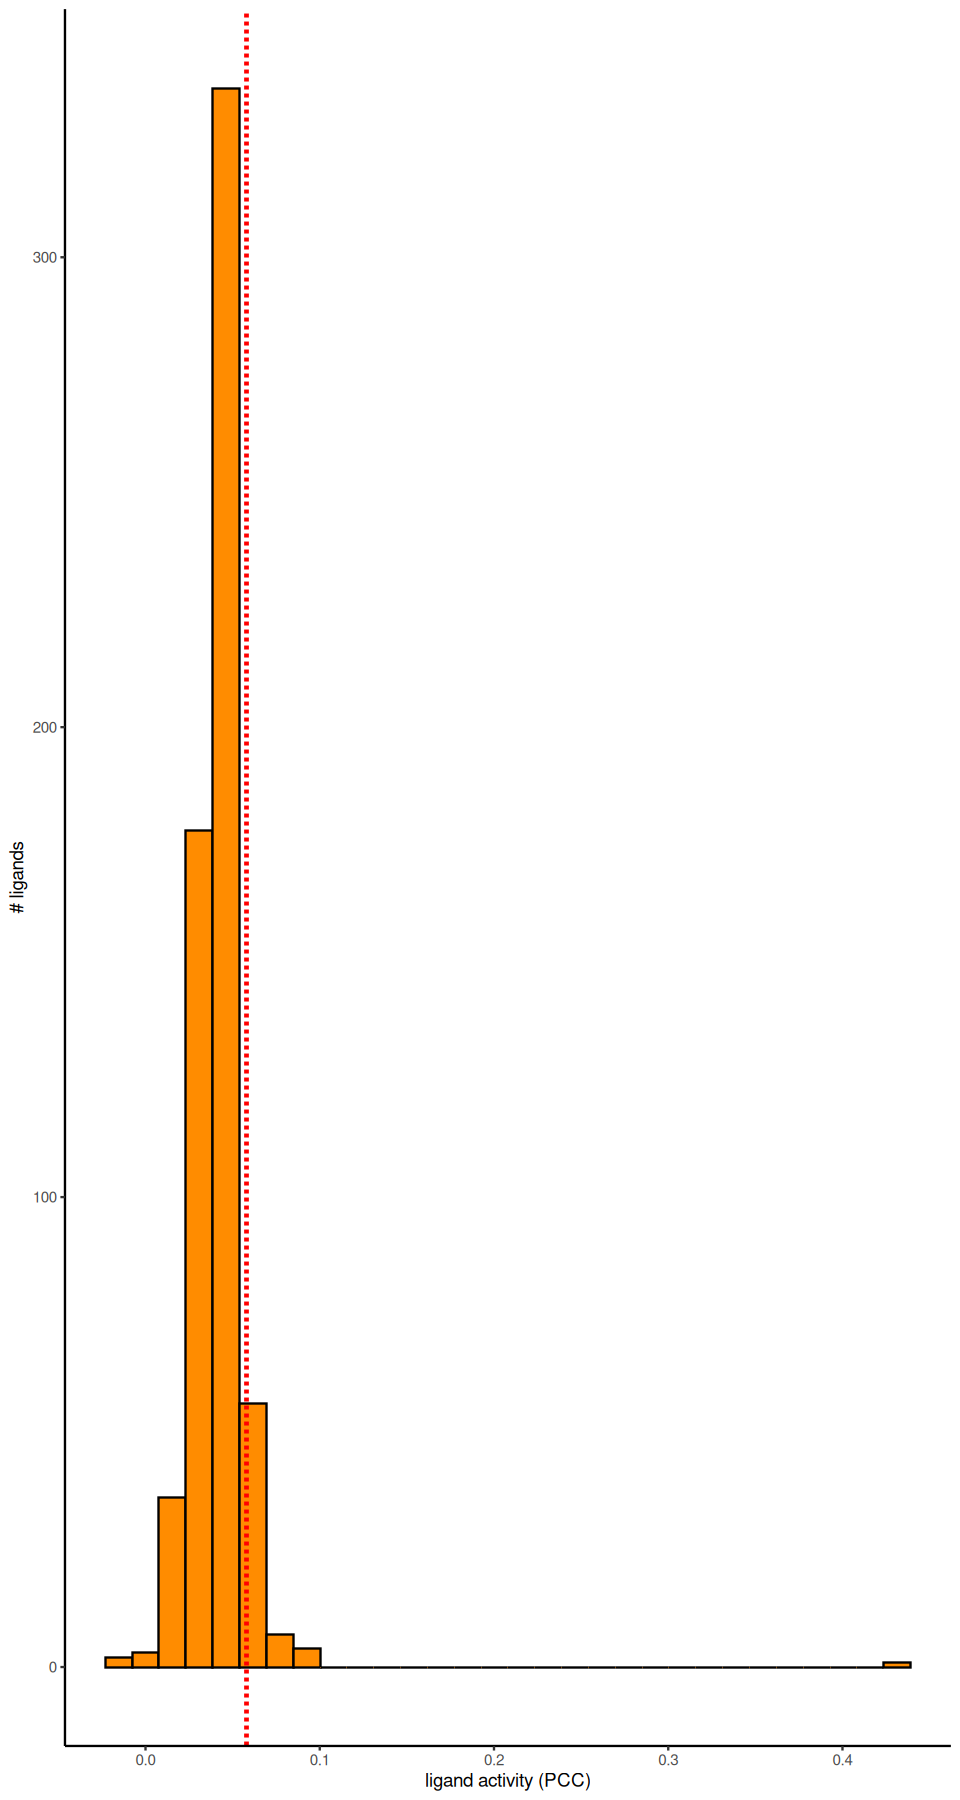

In [90]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [92]:
best_upstream_ligands <- ligand_activities %>% top_n(51, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [93]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

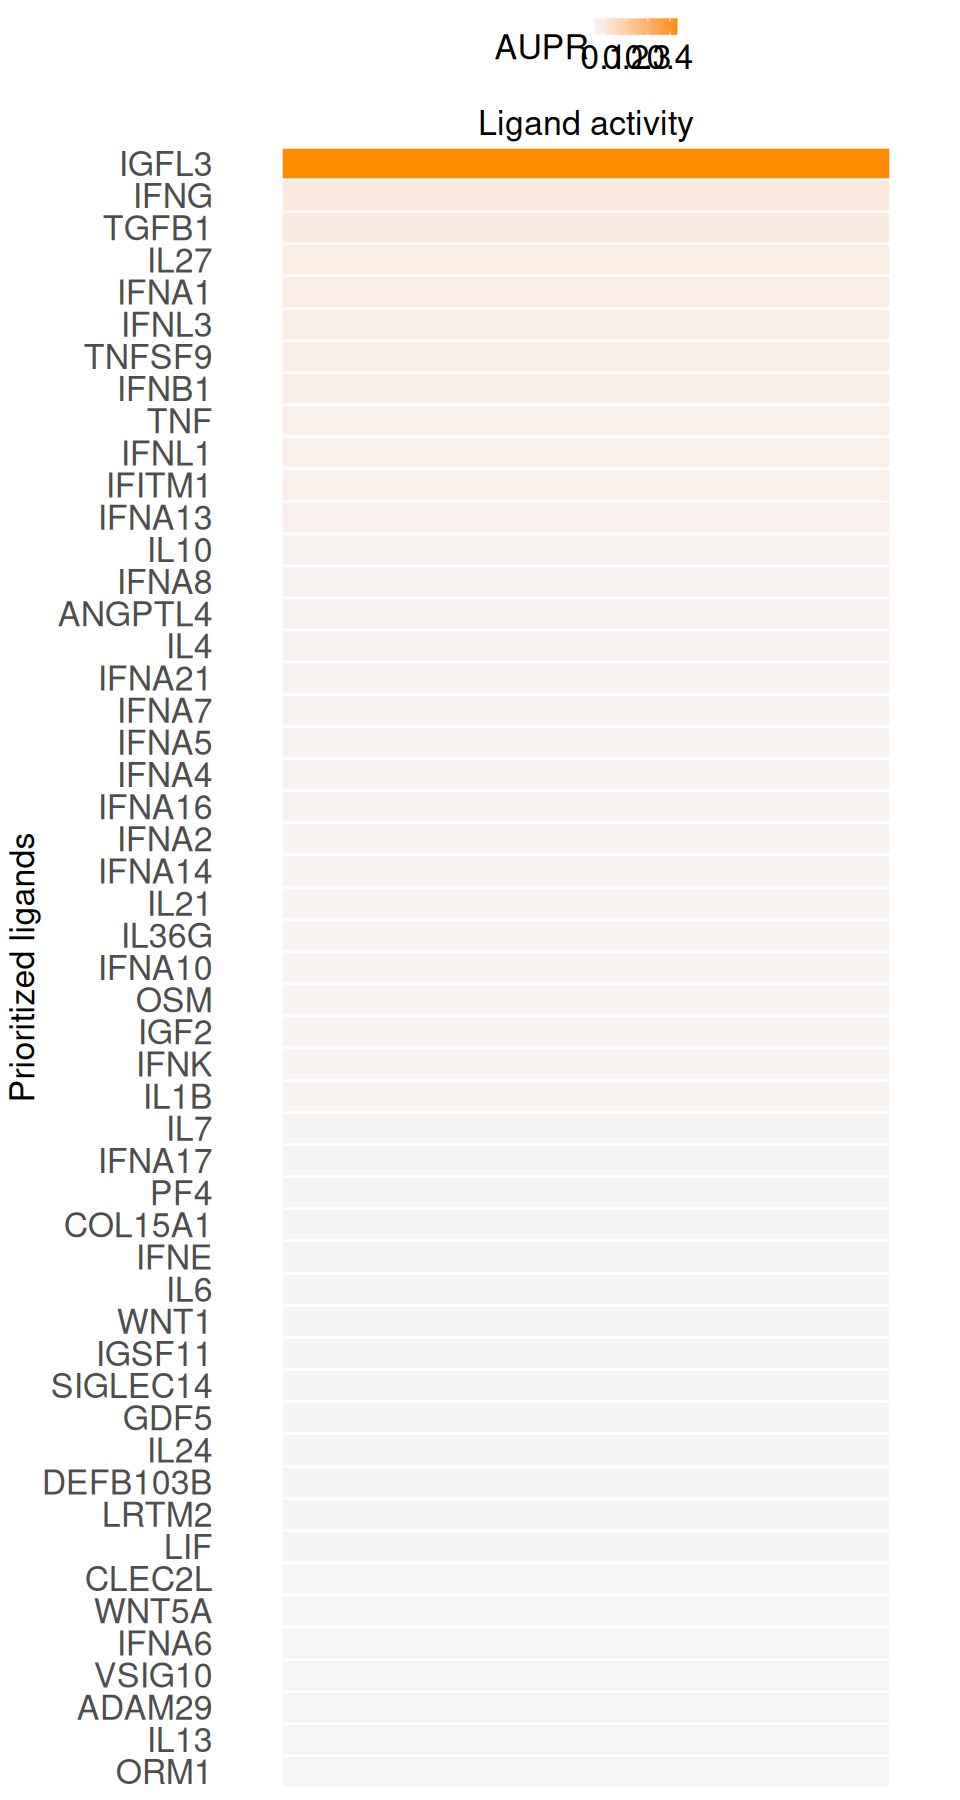

In [94]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()

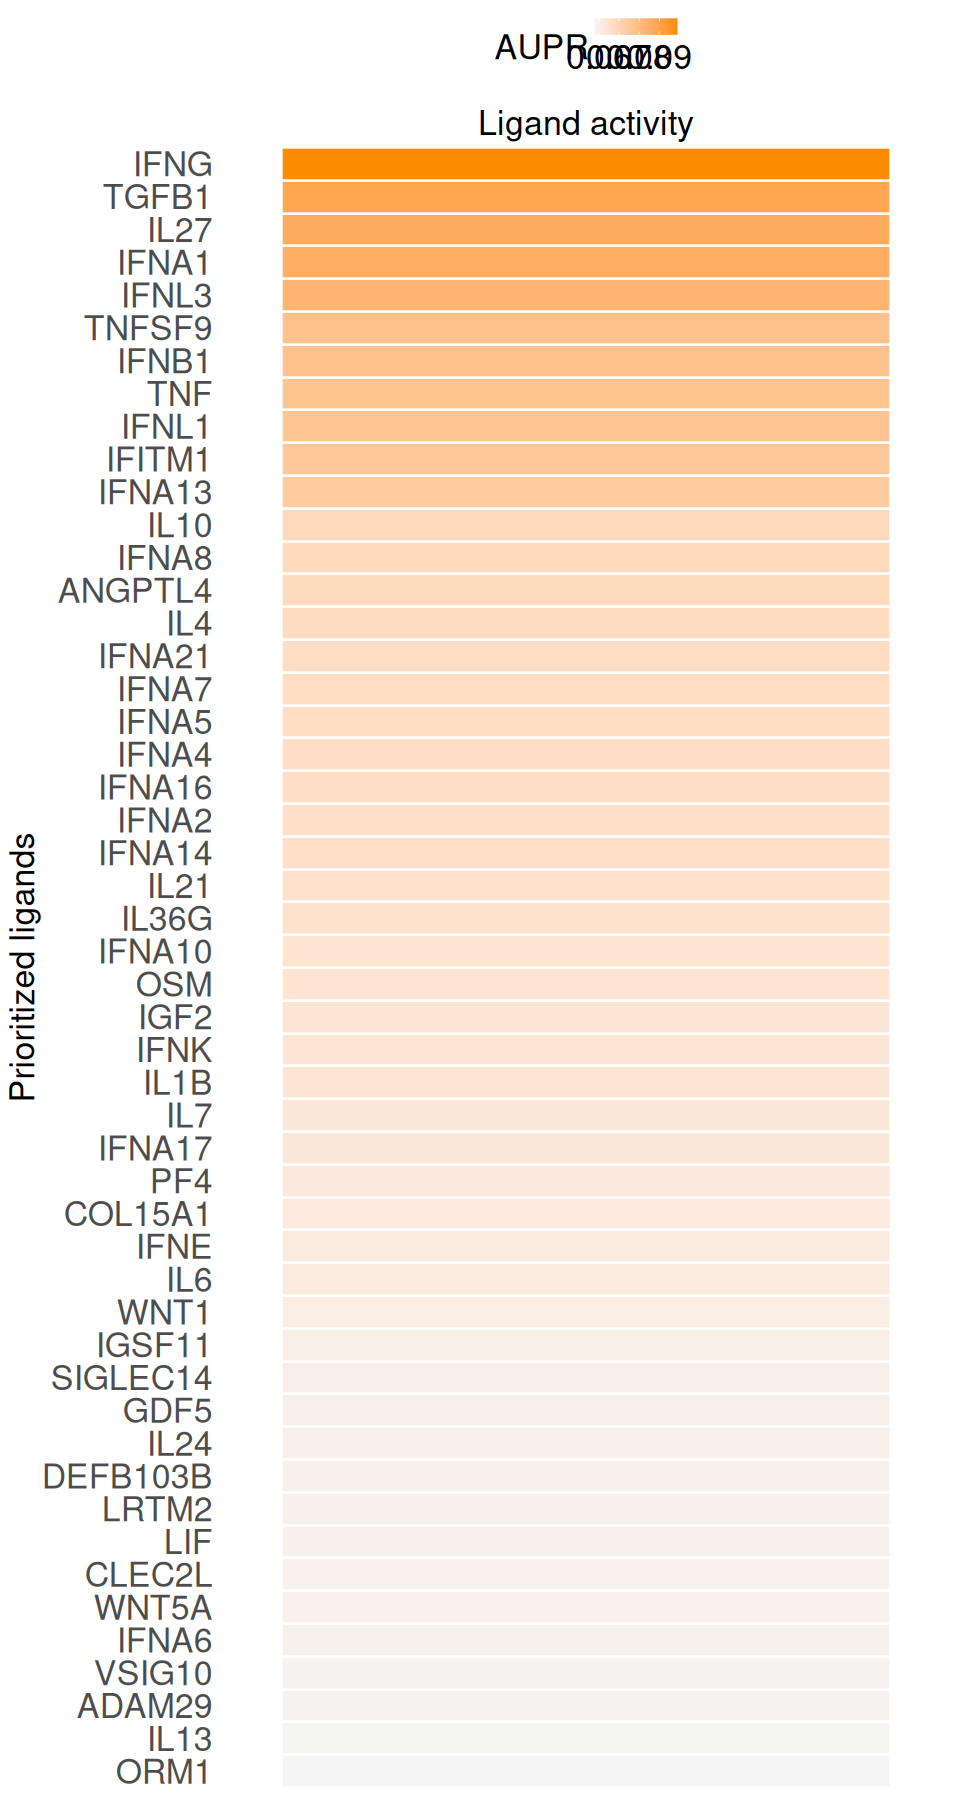

In [95]:
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands & test_ligand != "IGFL3") %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank()))  + ggtheme()

In [97]:
ligands_5p  <- c(best_upstream_ligands[2:51])
ligands_3p  <- c('IFNB1', 'IL27', 'IFNL3', 'IFNG', 'IFNL1', 'IL3', 'IFNA1', 'EBI3', 'IFNA16', 'IFNA5', 'IFNA21', 'IFNL2', 'IFNE', 'IFNA2', 'IFNA4', 'IFNA7', 'IFNA14', 'LTB', 'IL12A', 'IL21', 'IFNK', 'IFNA10', 'IFNL4', 'IFNA8', 'IL24', 'IFNA17', 'TSLP', 'IL10', 'IL12B', 'IL26', 'OSM', 'IFNA6', 'IL23A', 'TNF', 'IL11', 'IL22', 'IL36G', 'SIGLEC6', 'IL6', 'IL9', 'CLCF1', 'PTPRC', 'SIGLEC14', 'IFNA13', 'CXCL12', 'VSIG10', 'HLA-DRB5', 'IL4', 'CNTF', 'LIF', 'IFNW1', 'TGFB1', 'IL7', 'IFITM1', 'IL18', 'IL13', 'BTLA', 'UCN3', 'TNFSF4', 'CCL2', 'IL15', 'IL37', 'HLA-G', 'JAM2', 'CD40', 'CRLF1', 'TNFSF12', 'LTA', 'TNFSF14', 'BMP8A', 'HLA-E', 'NECTIN3', 'MMP1', 'TGFB2', 'LAMA2', 'TGM2', 'TNFRSF14', 'SIRPA', 'MMP9', 'TIMP1', 'COL12A1', 'TCN1', 'SELP', 'SELE', 'HLA-DMB', 'IL1F10', 'VTCN1', 'SFTPD', 'RECK', 'CLEC4G', 'CD40LG', 'KIR2DL5A', 'MICB', 'COL26A1', 'SIGLEC9', 'ADAM17', 'COL4A1', 'CCL11', 'COL10A1', 'ICOSLG', 'CD28', 'TNFSF13', 'HLA-A', 'CD86', 'SIGLEC1', 'HBEGF', 'MDK', 'CCL3', 'COL5A1', 'LRRN2', 'UCN2', 'CD72', 'B2M', 'CCL5', 'FASLG', 'CCL3L1', 'CD70', 'TNFSF18', 'SDC2', 'ZG16B', 'COL18A1', 'CLEC2D', 'MATN1', 'ANGPT2', 'SIGLEC7', 'CCL20', 'HLA-B', 'HMGB1', 'DEFB103B', 'ALCAM', 'CD5L', 'MUC7')[1:50]
ligands_thomas  <- c(
  "IFNG", "IL27", "IL21", "IL4", "IL1B", "ANGPT2", "IFNA1", "IL10", "OSM", "TNFSF9", "JAM2", "IL6","CD274", "RSPO3", "IFNA13", 
  "TNF","TSLP","BDNF", "IL15", "IL12A", "CCL3", "IFNA7", "SIGLEC9", "IFNA16", "SIGLEC7", "OCLN", "IFNB1", "IFNK", "IL21B", 
    "EBI3", "IFNA2",
  "CX3CL1", "DEFB103B", "JAM3", "IFNA5","IFNA14", "IL13", "VSIG10", "CD40LG", "CXCL12", "SIGLEC14", "IFNA8", "IL2",
  "PTPRC", "LILRB2", "IFNA4", "KIR2DL5A", "TNFSF12", "COL19A1", "IL36LG")

In [98]:
length(ligands_3p)
length(ligands_5p)
length(ligands_thomas)


[1] 50

[1] 50

[1] 50

In [103]:
ligands_all  <- data.frame(ligand = c(ligands_3p, ligands_5p, ligands_thomas),
                           rank = c(1:50,1:50,1:50),
                          dataset = c(rep("Predict_3p", times = 50), 
                                      rep("Predict_5p", times = 50), 
                                      rep("Thomas", times = 50)))

In [105]:
ligands_all  %>% pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)  

ligand,Predict_3p,Predict_5p,Thomas
<chr>,<int>,<int>,<int>
IFNB1,1,7,27
IL27,2,3,2
IFNL3,3,5,100
IFNG,4,1,1
IFNL1,5,9,100
IL3,6,100,100
IFNA1,7,4,7
EBI3,8,100,30
IFNA16,9,20,24


In [110]:
ligands_all  %>% pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)  %>% 
pivot_longer(!ligand, names_to = "dataset", values_to = "rank")  %>% 
group_by(ligand)  %>% 
summarise(mean_rank = mean(rank))  %>% 
arrange(mean_rank)

ligand,mean_rank
<chr>,<dbl>
IFNG,2.000000
IL27,2.333333
IFNA1,6.000000
IFNB1,11.666667
IL21,15.333333
IL10,16.000000
IFNA16,17.666667
IFNA7,18.333333
TNF,19.333333


In [ ]:
ligands_intersection = intersect(intersect(ligands_3p, ligands_5p), ligands_thomas)

ligands_intersection

In [113]:
ligands_all  %>% dplyr::filter(ligand %in% ligands_intersection)  %>% 
group_by(ligand)  %>% 
summarise(mean_rank = mean(rank))  %>% 
arrange(mean_rank)

ligand,mean_rank
<chr>,<dbl>
IFNG,2.000000
IL27,2.333333
IFNA1,6.000000
IFNB1,11.666667
IL21,15.333333
IL10,16.000000
IFNA16,17.666667
IFNA7,18.333333
TNF,19.333333


In [118]:
ligands_all  %>% dplyr::filter(ligand %in% ligands_intersection)  %>% 
pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)   %>% 
mutate(avg_rank = rowMeans(across(c(Predict_3p, Predict_5p, Thomas))))  %>% 
arrange(avg_rank)

ligand,Predict_3p,Predict_5p,Thomas,avg_rank
<chr>,<int>,<int>,<int>,<dbl>
IFNG,4,1,1,2.000000
IL27,2,3,2,2.333333
IFNA1,7,4,7,6.000000
IFNB1,1,7,27,11.666667
IL21,20,23,3,15.333333
IL10,28,12,8,16.000000
IFNA16,9,20,24,17.666667
IFNA7,16,17,22,18.333333
TNF,34,8,16,19.333333


In [120]:
lig_test  <- ligands_all  %>% dplyr::filter(ligand %in% ligands_intersection)  %>% 
pivot_wider(names_from = dataset, values_from = rank, values_fill = 100)   %>% 
mutate(avg_rank = rowMeans(across(c(Predict_3p, Predict_5p, Thomas))))  %>% 
arrange(avg_rank)  %>% 
dplyr::select(-avg_rank)  %>% 
column_to_rownames("ligand")  %>% 
as.matrix()

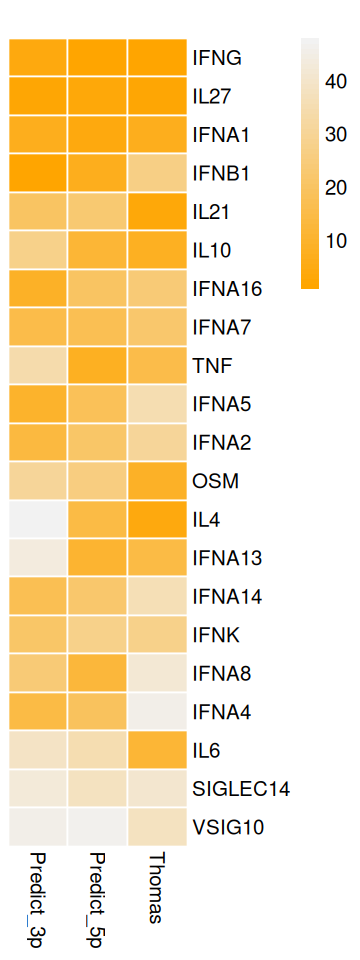

In [129]:
options(repr.plot.width = 3, repr.plot.height = 8)
pheatmap::pheatmap(lig_test, main = "", 
         scale = "none", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("orange", "grey95"))(50), 
         border_color = "white",
                  fontsize = 12)

In [131]:
seu_ile_lp_filt$cell_type_lvl1  %>% table

.
               B Cells                    DCs      Endothelial Cells 
                133605                   5466                  12220 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                   221                  55076                    393 
            Epithelial            Fibroblasts                   Glia 
                 41991                  30344                   1749 
          Goblet Cells                   ILCs            Macrophages 
                 10282                   5227                  30493 
                  Mast                     NK           Paneth Cells 
                 17045                  11046                   6067 
                  pDCs              Pericytes           Plasma Cells 
                  1791                   1708                  80669 
         Proliferating                T Cells             Tuft Cells 
                  4554                 222624                    249 

In [132]:
colnames(seu_ile_lp_filt@meta.data)

[1] "orig.ident"                      "nCount_RNA"                     
 [3] "nFeature_RNA"                    "bc"                             
 [5] "data_folder"                     "data_folder2"                   
 [7] "sample"                          "diagnosis"                      
 [9] "subgroup_primary"                "subgroup_secondary"             
[11] "subgroup_tertiary"               "Rome_coarse"                    
[13] "Rome_classification"             "antitnf_response"               
[15] "participant_id"                  "timepoint"                      
[17] "age"                             "sex"                            
[19] "site"                            "tissue"                         
[21] "layer"                           "prime"                          
[23] "version_10x"                     "sample_old"                     
[25] "data_type"                       "seq_run"                        
[27] "collection_purpose"              "collection_date"                
[29] "days"                            "antitnf"                        
[31] "antitnf_repeat"                  "duo_inflammation"               
[33] "ile_inflammation"                "col_inflammation"               
[35] "sample_inflamed"                 "colon_site"                     
[37] "score_type"                      "severity_score"                 
[39] "weighted_severity_score"         "severity_score_date"            
[41] "severity_score_range"            "weighted_score_range"           
[43] "internal_flag"                   "cell_lineage"                   
[45] "cell_type_lvl1"                  "cell_type_lvl2"                 
[47] "cell_state"                      "keep"                           
[49] "annotations"                     "cd4_ctl"                        
[51] "combinedMajorTypes_plus_cd4_ctl" "cellsubsets_plus_cd4_ctl"

In [193]:
aggexp_5p  <- AggregateExpression(seu_ile_lp_filt, group.by = c("data_folder", "cell_type_lvl1"), 
                                 features = c(ligand_activities %>% filter(test_ligand %in% best_upstream_ligands)   %>%
                                              pull(test_ligand)),
                               return.seurat = T) 

Centering and scaling data matrix



In [134]:
aggexp_5p  <- NormalizeData(aggexp_5p)

aggexp_5p  <- ScaleData(aggexp_5p)

meta_aggexp_5p  <- AggregateExpression(aggexp_5p, group.by = c("cell_type_lvl1"), slot = "counts",
                                  features = rownames(aggexp_5p), assay= "RNA",
                               return.seurat = F)

Normalizing layer: counts

Centering and scaling data matrix



In [140]:
mtx  <- meta_aggexp_5p$RNA[which(rowSums(meta_aggexp_5p$RNA)>0),]

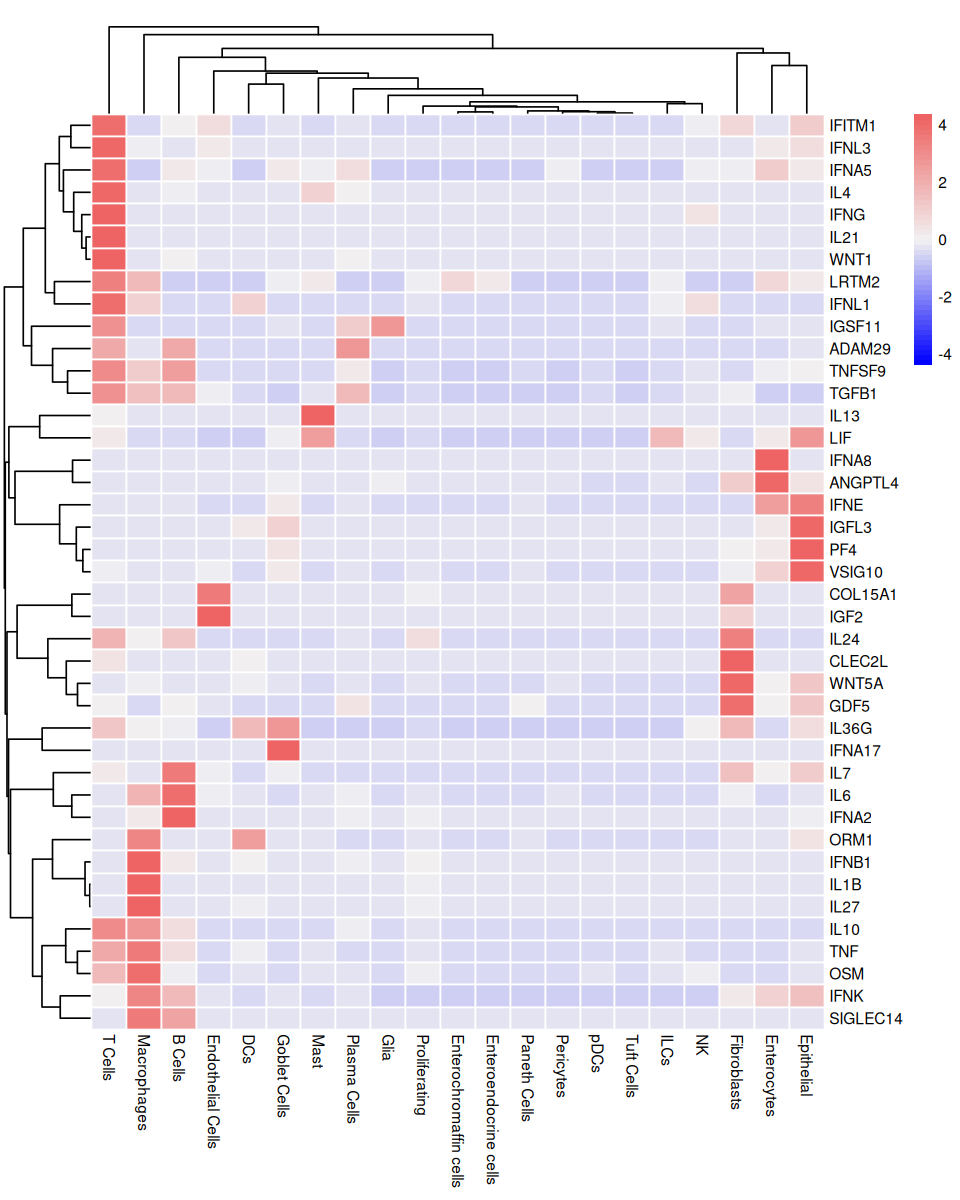

In [143]:
options(repr.plot.width = 8, repr.plot.height = 10)

pheatmap::pheatmap(mtx, main = "", 
         scale = "row", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5)

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 3.5)
pheatmap::pheatmap(t(meta_aggexp_5p$RNA)[c(6,1,8,4,3,2,5,7),], main = "", 
         scale = "column", cluster_cols = T, cluster_rows = F,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5,
                  filename = "figures/ligand_receptor/predict5p_ligand_expression_heatmap.pdf")

In [148]:
saveRDS(seu_ile_lp_filt, "data/seu_ile_lp_filt.rds")

In [151]:
saveRDS(aggexp_5p, "data/seu_ile_lp_filt_aggexp_5p.rds")

In [144]:
ligands_5p

[1] "IFNG"     "TGFB1"    "IL27"     "IFNA1"    "IFNL3"    "TNFSF9"  
 [7] "IFNB1"    "TNF"      "IFNL1"    "IFITM1"   "IFNA13"   "IL10"    
[13] "IFNA8"    "ANGPTL4"  "IL4"      "IFNA21"   "IFNA7"    "IFNA5"   
[19] "IFNA4"    "IFNA16"   "IFNA2"    "IFNA14"   "IL21"     "IL36G"   
[25] "IFNA10"   "OSM"      "IGF2"     "IFNK"     "IL1B"     "IL7"     
[31] "IFNA17"   "PF4"      "COL15A1"  "IFNE"     "IL6"      "WNT1"    
[37] "IGSF11"   "SIGLEC14" "GDF5"     "IL24"     "DEFB103B" "LRTM2"   
[43] "LIF"      "CLEC2L"   "WNT5A"    "IFNA6"    "VSIG10"   "ADAM29"  
[49] "IL13"     "ORM1"

In [158]:
seu_ile_lp_filt$cell_type_lvl1_and_cd4_ctl  <- ifelse(seu_ile_lp_filt$cd4_ctl,"CD4_CTL", seu_ile_lp_filt$cell_type_lvl1)

In [157]:
seu_ile_lp_filt$cd4_ctl  %>% table

.
 FALSE   TRUE 
666876   5944 

In [159]:
seu_ile_lp_filt$cell_type_lvl1_and_cd4_ctl  %>% table

.
               B Cells                CD4_CTL                    DCs 
                133605                   5944                   5466 
     Endothelial Cells Enterochromaffin cells            Enterocytes 
                 12220                    221                  55076 
 Enteroendocrine cells             Epithelial            Fibroblasts 
                   393                  41991                  30344 
                  Glia           Goblet Cells                   ILCs 
                  1749                  10282                   5227 
           Macrophages                   Mast                     NK 
                 30493                  17045                  11046 
          Paneth Cells                   pDCs              Pericytes 
                  6067                   1791                   1708 
          Plasma Cells          Proliferating                T Cells 
                 80669                   4554                 216680 
            Tuft C

In [160]:
ligand_type_indication_df <- assign_ligands_to_celltype(seu_ile_lp_filt, ligands_5p , celltype_col = "cell_type_lvl1")

Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assay]], layer = layer):
“data layer is not found and counts layer is used”
Warning message in GetAssayData.StdAssay(object = object[[assa

In [161]:
 active_ligand_target_links_df <- lapply(best_upstream_ligands, 
                                         get_weighted_ligand_target_links, geneset = geneset_oi, 
                                         ligand_target_matrix = ligand_target_matrix, n = 200) 
active_ligand_target_links_df <- drop_na(bind_rows(active_ligand_target_links_df)) 

In [162]:
active_ligand_target_links <- prepare_ligand_target_visualization(ligand_target_df = active_ligand_target_links_df, 
                                                                  ligand_target_matrix = ligand_target_matrix, 
                                                                  cutoff = 0.25)

In [163]:
active_ligand_target_links

,PF4,GDF5,ANGPTL4,IGF2,TNFSF9,WNT1,IL7,WNT5A,IL24,TGFB1,⋯,IFNA16,IFNE,IFITM1,IFNA2,IGSF11,ORM1,COL15A1,CLEC2L,DEFB103B,ADAM29
CLPTM1L,0.002330017,0.003015990,0.003917336,0.004630184,0.002742292,0.003046000,0.004934491,0.002676363,0.005343928,0.004240124,⋯,0.003841381,0.003683518,0.002940329,0.004223004,0.002104447,0.002893165,0.002818950,0.001792317,0.001503478,0.001982063
PPFIA1,0.001881841,0.002611163,0.003671325,0.004217136,0.002655032,0.002242653,0.002943369,0.002098676,0.003830427,0.003704276,⋯,0.003287606,0.003247068,0.002483552,0.003619019,0.001766182,0.003627470,0.002382895,0.001665172,0.001219344,0.001529191
ECPAS,0.002228795,0.002458274,0.004517146,0.004455679,0.002201056,0.002833593,0.003539639,0.003089566,0.004968684,0.003805274,⋯,0.003909509,0.003422076,0.002963994,0.004130664,0.004182259,0.003365642,0.002539067,0.002128687,0.001403585,0.001938992
TXNL4A,0.002150327,0.003359207,0.005068601,0.004886393,0.003062432,0.002770004,0.003866097,0.003110057,0.005406024,0.004337188,⋯,0.003751953,0.003787477,0.005545799,0.004272973,0.002853175,0.002819299,0.002559884,0.001965784,0.001600751,0.001828965
MICAL3,0.002084368,0.002627461,0.003972697,0.004793752,0.002177033,0.002858935,0.003910060,0.002478175,0.004657586,0.004192119,⋯,0.003558403,0.003524655,0.004044580,0.004017956,0.003923851,0.003815446,0.003312643,0.002479543,0.001416877,0.001641217
EEPD1,0.002220129,0.003177752,0.004137426,0.005354335,0.002564437,0.003291926,0.003898857,0.003426870,0.007048813,0.005234732,⋯,0.004569268,0.004228489,0.005392777,0.004758999,0.006980949,0.003092555,0.003112890,0.002953142,0.001519988,0.001870844
LDB1,0.003341972,0.005267292,0.006535804,0.007701092,0.004551093,0.005277647,0.005912358,0.004571995,0.009552471,0.006913832,⋯,0.005731191,0.005125753,0.005395690,0.006136640,0.009078785,0.007663707,0.004918756,0.003892237,0.002154078,0.002945394
CTNNA1,0.003323003,0.004702854,0.006480919,0.008004362,0.004840396,0.004264454,0.005593576,0.004259448,0.010234332,0.007317579,⋯,0.006997943,0.007256812,0.006550465,0.007017689,0.006217177,0.004539887,0.004520902,0.003355743,0.002317325,0.002856155
DNAJC21,0.001672434,0.002447589,0.004113482,0.004810462,0.002962859,0.002590650,0.003468382,0.002354671,0.005914714,0.003725381,⋯,0.003919568,0.003542009,0.003549365,0.003873567,0.003518441,0.002281620,0.002325764,0.002101062,0.001181953,0.001967638
FBXO2,0.002392563,0.003439655,0.004921571,0.005595034,0.003509376,0.003112358,0.003542797,0.003060419,0.005750319,0.004591129,⋯,0.004093127,0.005051119,0.004769731,0.004427993,0.005157739,0.003050741,0.003370399,0.002415236,0.001523501,0.002095727


In [164]:
ligand_type_indication_df  %>% dplyr::filter(ligand == "IL27")

ligand_type,ligand
<chr>,<chr>
DCs,IL27


In [165]:
ligand_type_indication_df$ligand_type  %>% table

.
               B Cells                    DCs      Endothelial Cells 
                     1                      4                      4 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                     1                      2                      1 
            Epithelial            Fibroblasts                General 
                     1                      2                     25 
                  Glia           Goblet Cells                   ILCs 
                     2                      3                      1 
           Macrophages                   Mast                     NK 
                     7                      3                      1 
          Paneth Cells                   pDCs              Pericytes 
                     1                      1                      1 
          Plasma Cells          Proliferating                T Cells 
                     3                      3                      3 
            Tuft C

In [166]:
 active_ligand_target_links_df$target_type <- "CD4_CTL"
circos_links <- get_ligand_target_links_oi(ligand_type_indication_df, active_ligand_target_links_df, cutoff = 0.40) 

Joining with `by = join_by(ligand)`


In [167]:
 active_ligand_target_links_df$target_type <- "CD4_CTL"


In [172]:
circos_links$ligand_type  %>% table

.
              DCs Endothelial Cells       Enterocytes       Fibroblasts 
              105                27                59                15 
          General      Goblet Cells       Macrophages              Mast 
             1125               101               282                78 
     Plasma Cells     Proliferating           T Cells 
               79                48                90 

In [171]:
circos_links

ligand,target,weight,target_type,ligand_type
<chr>,<chr>,<dbl>,<chr>,<chr>
IFNG,A2M,0.1383269,CD4_CTL,General
IFNG,ABCA1,0.1516841,CD4_CTL,General
IFNG,ADAR,0.1915551,CD4_CTL,General
IFNG,AIM2,0.1754083,CD4_CTL,General
IFNG,B4GALT5,0.1854809,CD4_CTL,General
IFNG,BTN3A1,0.1931506,CD4_CTL,General
IFNG,CASP7,0.1815108,CD4_CTL,General
IFNG,CD274,0.1729398,CD4_CTL,General
IFNG,CD40,0.1754382,CD4_CTL,General


In [168]:
active_ligand_target_links_df

ligand,target,weight,target_type
<chr>,<chr>,<dbl>,<chr>
IGFL3,A2M,0,CD4_CTL
IGFL3,ABCA1,0,CD4_CTL
IGFL3,ABCA2,0,CD4_CTL
IGFL3,ABCB10,0,CD4_CTL
IGFL3,ABCC1,0,CD4_CTL
IGFL3,ABHD17A,0,CD4_CTL
IGFL3,ABTB2,0,CD4_CTL
IGFL3,ACBD3,0,CD4_CTL
IGFL3,ACCS,0,CD4_CTL


In [173]:
circos_links$ligand_type  %>% table

.
              DCs Endothelial Cells       Enterocytes       Fibroblasts 
              105                27                59                15 
          General      Goblet Cells       Macrophages              Mast 
             1125               101               282                78 
     Plasma Cells     Proliferating           T Cells 
               79                48                90 

In [ ]:
ligand_colors <- c("General" = "goldenrod", "Fibro" = "#09bd5fff", 
                    "Mstcl" = "#00bfc4ff", "Myeloid" = "#00a9ffff", 
                    "T" = "#ff60ccff", "DC") 

target_colors <- c("CD4_CTL" = "#999999") 

vis_circos_obj <- prepare_circos_visualization(circos_links, ligand_colors = ligand_colors, target_colors = target_colors) 

In [174]:
vis_circos_obj <- prepare_circos_visualization(circos_links) 

Joining with `by = join_by(ligand_type)`
Joining with `by = join_by(target_type)`


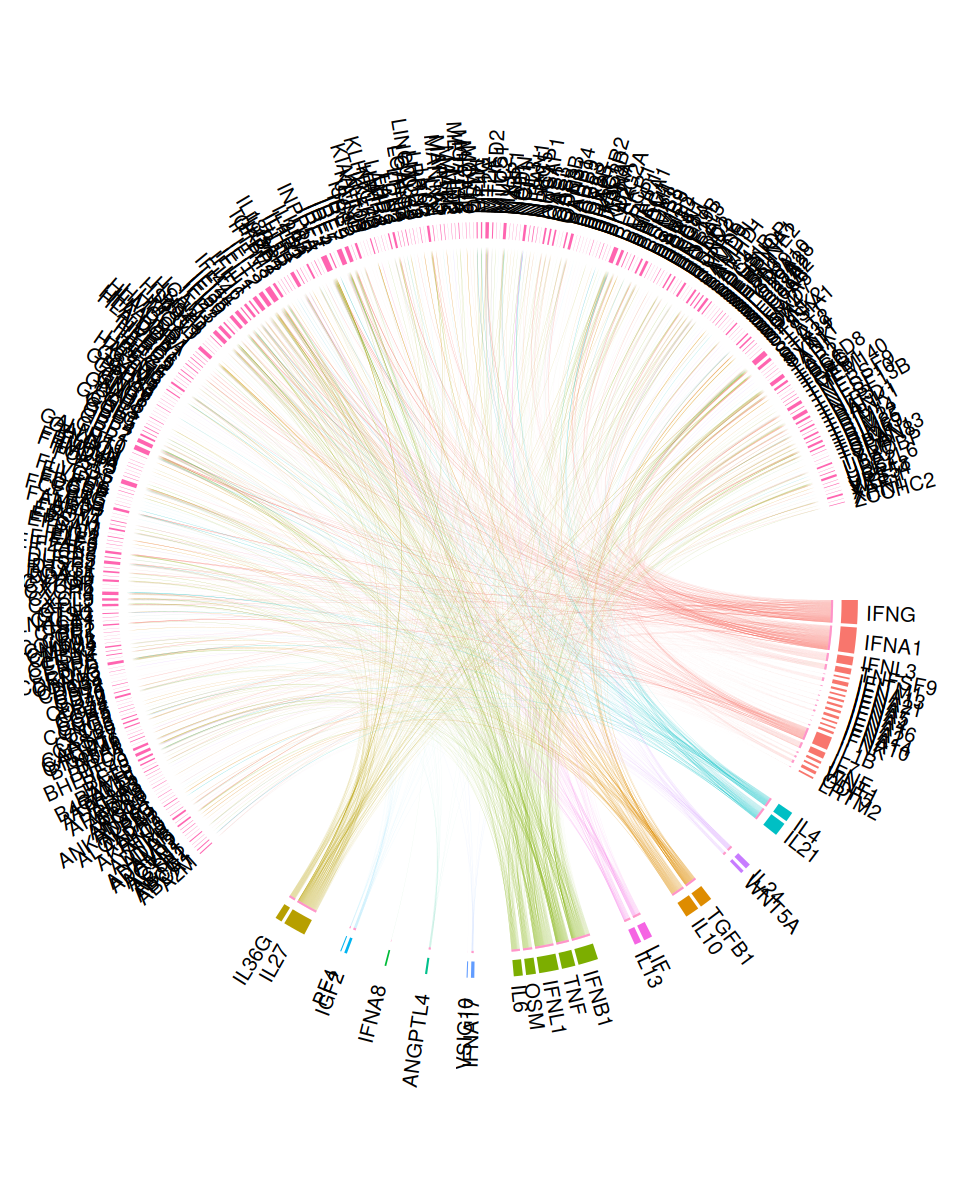

In [175]:
make_circos_plot(vis_circos_obj, transparency = TRUE) 

In [176]:
aggexp_5p$data_folder

An object of class Seurat 
51 features across 2202 samples within 1 assay 
Active assay: RNA (51 features, 0 variable features)
 3 layers present: counts, data, scale.data

In [190]:
md_to_join  <- seu_ile_lp@meta.data   %>% 
group_by(data_folder, participant_id, diagnosis, tissue, layer, antitnf_response, timepoint)  %>% 
tally  %>% 
dplyr::select(-n)  %>% 
ungroup

In [212]:
md  <- aggexp_5p@meta.data  %>% dplyr::select(data_folder, cell_type_lvl1)  %>%  left_join(md_to_join)

Joining with `by = join_by(data_folder)`


In [211]:
table(aggexp_5p$data_folder %in% md_to_join$data_folder)


TRUE 
2202 

In [213]:
md

data_folder,cell_type_lvl1,participant_id,diagnosis,tissue,layer,antitnf_response,timepoint
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
g003-043-T0-ILE-LP-5p-GEX,B Cells,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,DCs,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Endothelial Cells,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Enterochromaffin cells,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Enterocytes,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Enteroendocrine cells,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Epithelial,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Fibroblasts,003-043,FGID,ILE,LP,NM,T0
g003-043-T0-ILE-LP-5p-GEX,Glia,003-043,FGID,ILE,LP,NM,T0


In [204]:
md_to_join$data_folder  <- gsub(md_to_join$data_folder, pattern = "_", replacement = "-")

In [209]:
md_to_join$data_folder  <- paste0("g", md_to_join$data_folder)

In [210]:
md_to_join$data_folder  <- gsub(md_to_join$data_folder, pattern = "gHE", replacement = "HE")

In [214]:
rownames(md)  <- colnames(aggexp_5p)

aggexp_5p@meta.data  <- md

In [195]:
aggexp_5p$cell_type_lvl1  %>% table

.
               B Cells                    DCs      Endothelial Cells 
                   111                    113                    111 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                    67                    112                     85 
            Epithelial            Fibroblasts                   Glia 
                   113                    112                     90 
          Goblet Cells                   ILCs            Macrophages 
                   112                    111                    112 
                  Mast                     NK           Paneth Cells 
                   111                    113                    107 
                  pDCs              Pericytes           Plasma Cells 
                   106                    103                    113 
         Proliferating                T Cells             Tuft Cells 
                   112                    113                     75 

In [215]:
aggexp_5p$diagnosis  %>% table

.
     CD    FGID     HEA     OTH      UC Unknown 
   1072     460     181      68     381      40 

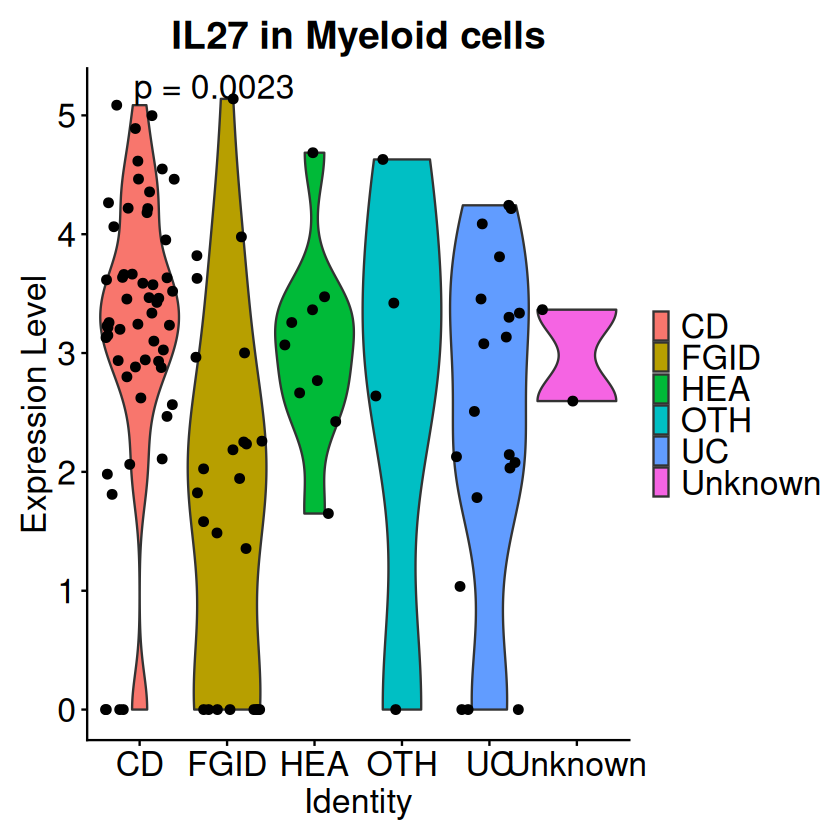

In [216]:
options(repr.plot.width = 7, repr.plot.height = 7)

VlnPlot(subset(aggexp_5p, cell_type_lvl1 == "Macrophages"), features = "IL27", group.by = "diagnosis", pt.size = 2) +
ggpubr::stat_compare_means(label = "p.format", label.x = 1.3, size = 7) + ggtitle("IL27 in Myeloid cells") + ggtheme() +
theme(axis.text.x = element_text(angle = 0, hjust = 0.5))

In [218]:
aggexp_5p$cell_type_lvl1  %>% table

.
               B Cells                    DCs      Endothelial Cells 
                   111                    113                    111 
Enterochromaffin cells            Enterocytes  Enteroendocrine cells 
                    67                    112                     85 
            Epithelial            Fibroblasts                   Glia 
                   113                    112                     90 
          Goblet Cells                   ILCs            Macrophages 
                   112                    111                    112 
                  Mast                     NK           Paneth Cells 
                   111                    113                    107 
                  pDCs              Pericytes           Plasma Cells 
                   106                    103                    113 
         Proliferating                T Cells             Tuft Cells 
                   112                    113                     75 

Warning message:
“Removing 3 cells missing data for features requested”
Warning message:
“Removing 3 cells missing data for vars requested”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_compare_means()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


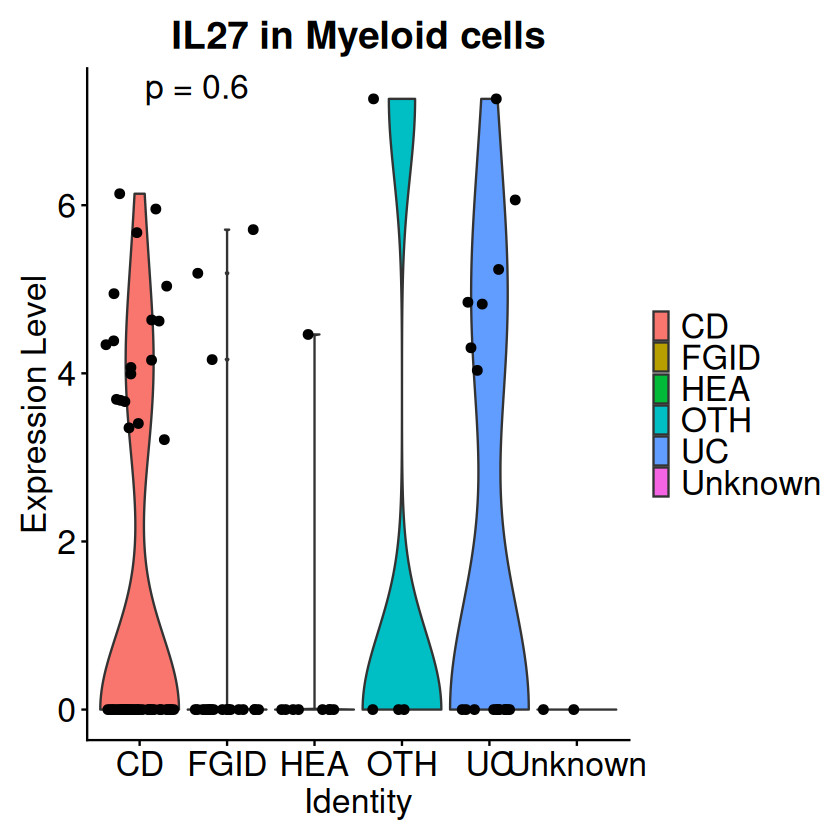

In [219]:
options(repr.plot.width = 7, repr.plot.height = 7)

VlnPlot(subset(aggexp_5p, cell_type_lvl1 == "DCs"), features = "IL27", group.by = "diagnosis", pt.size = 2) +
ggpubr::stat_compare_means(label = "p.format", label.x = 1.3, size = 7) + ggtitle("IL27 in Myeloid cells") + ggtheme() +
theme(axis.text.x = element_text(angle = 0, hjust = 0.5))

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


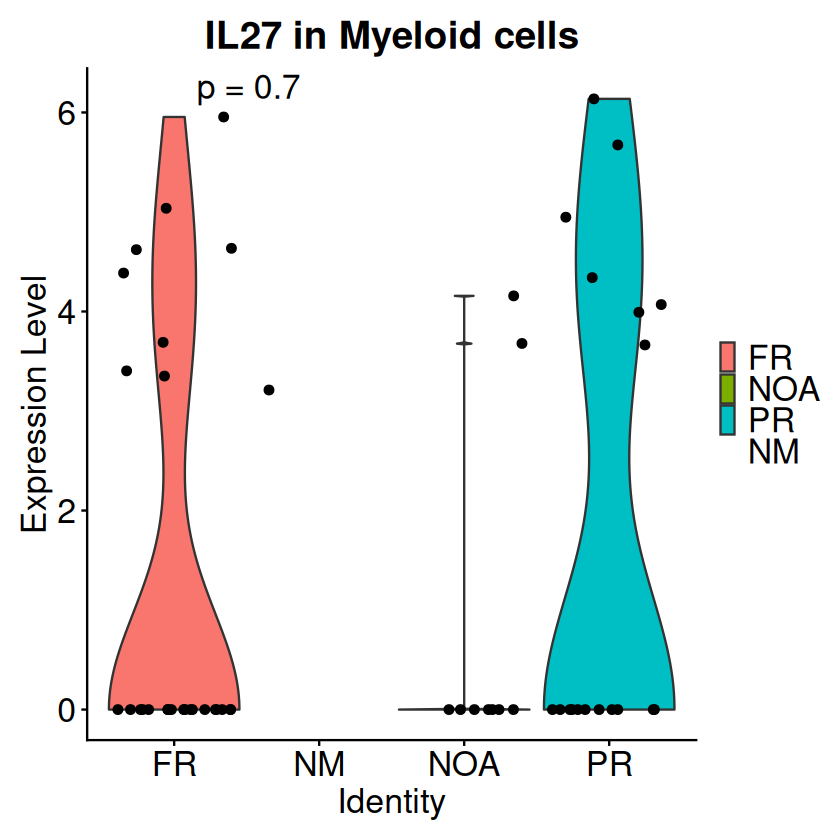

In [220]:
options(repr.plot.width = 7, repr.plot.height = 7)

VlnPlot(subset(aggexp_5p, cell_type_lvl1 == "DCs" & diagnosis == "CD"), features = "IL27", group.by = "antitnf_response", pt.size = 2) +
ggpubr::stat_compare_means(label = "p.format", label.x = 1.3, size = 7) + ggtitle("IL27 in Myeloid cells") + ggtheme() +
theme(axis.text.x = element_text(angle = 0, hjust = 0.5))

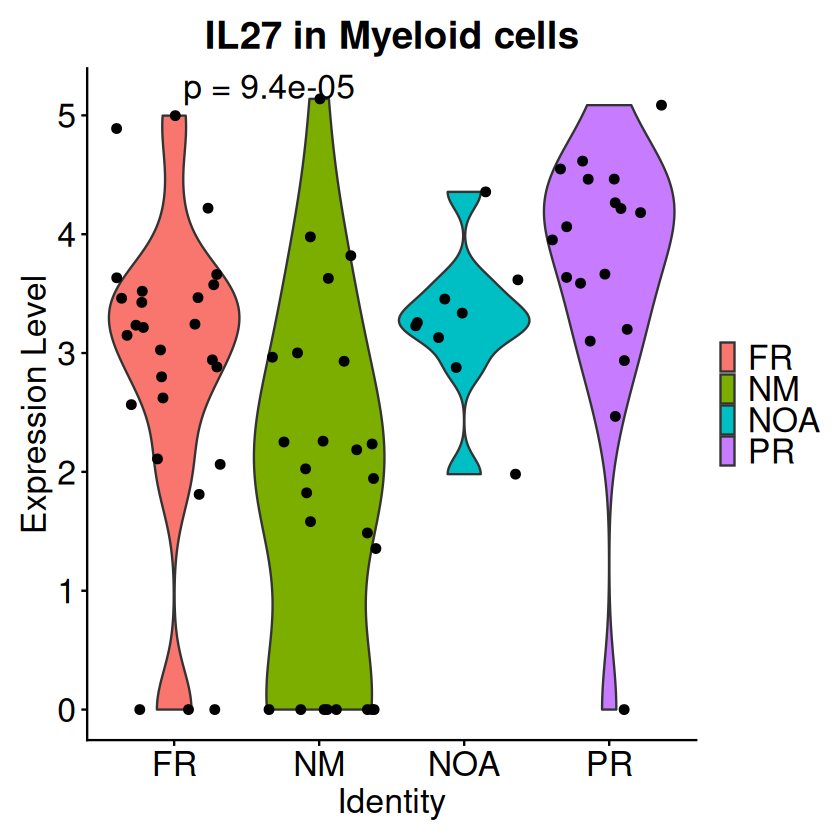

In [222]:
options(repr.plot.width = 7, repr.plot.height = 7)

VlnPlot(subset(aggexp_5p, cell_type_lvl1 == "Macrophages" & diagnosis %in% c("CD","FGID")), features = "IL27", group.by = "antitnf_response", pt.size = 2) +
ggpubr::stat_compare_means(label = "p.format", label.x = 1.3, size = 7) + ggtitle("IL27 in Myeloid cells") + ggtheme() +
theme(axis.text.x = element_text(angle = 0, hjust = 0.5))

In [224]:
pt_3p  <- gsub(c('p009',
'p011',
'p014',
'p016',
'p017',
'p018',
'p019',
'p022',
'p023',
'p024',
'p026',
'p027',
'p028',
'p030',
'p031',
'p032',
'p033',
'p034',
'p035',
'p037',
'p041',
'p042',
'p043',
'p044',
'p048',
'p049',
'p050'), pattern = "p", replacement = "001-")

In [ ]:
aggexp_5p$participant_id

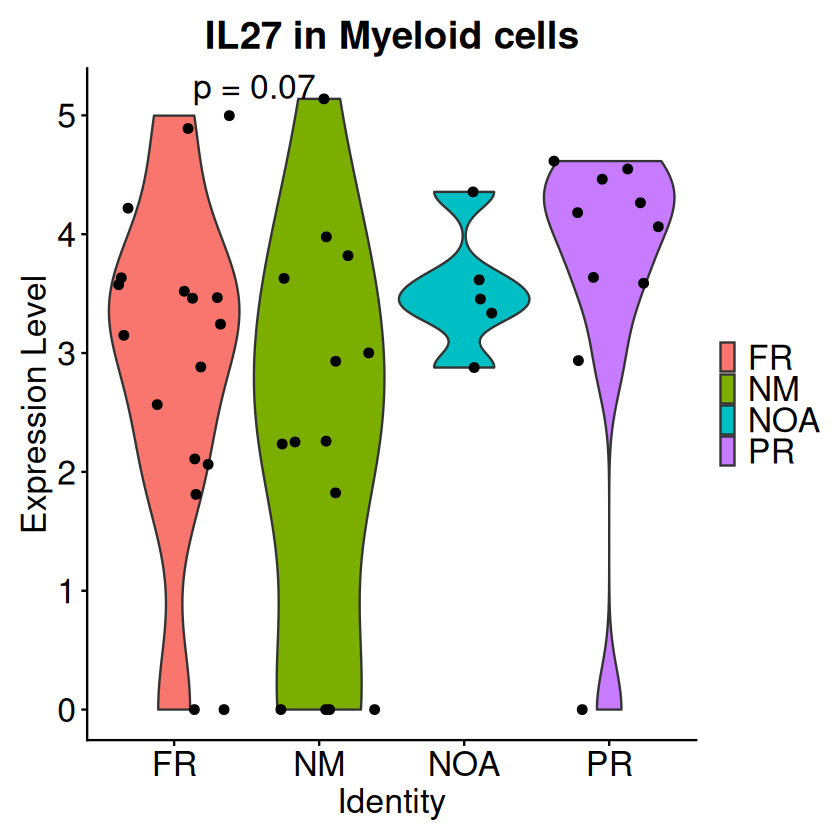

In [227]:
options(repr.plot.width = 7, repr.plot.height = 7)

VlnPlot(subset(aggexp_5p, cell_type_lvl1 == "Macrophages" & diagnosis %in% c("CD","FGID") & ((participant_id %in% pt_3p)==F)),
        features = "IL27", group.by = "antitnf_response", pt.size = 2) +
ggpubr::stat_compare_means(label = "p.format", label.x = 1.3, size = 7) + ggtitle("IL27 in Myeloid cells") + ggtheme() +
theme(axis.text.x = element_text(angle = 0, hjust = 0.5))

In [330]:
levels(factor(seu_ile_lp_filt$combinedMajorTypes))

ERROR: Error in (function (cond) : error in evaluating the argument 'x' in selecting a method for function 'levels': ‘combinedMajorTypes’ not found in this Seurat object
 Did you mean "combinedMajorTypes_plus_cd4_ctl"?


In [ ]:
sender_celltypes <- levels(factor(seu_ile_lp_filt$combinedMajorTypes))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, seu_ile_lp_filt, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

In [ ]:
list_expressed_genes_sender

In [ ]:
names(list_expressed_genes_sender)  <- levels(factor(seu_ile_lp_filt$combinedMajorTypes))

In [ ]:
names(list_expressed_genes_sender)

In [ ]:
list_expressed_genes_sender

In [ ]:
ligands <- lr_network %>% pull(from) %>% unique()